In [1]:
import pandas as pd
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter

# Base directory
base_dir = r"c:\Users\Steve\Desktop\Repo\Research\corn\V4"

# Get all folders except 'Before seed'
folders = [f for f in os.listdir(base_dir) 
           if os.path.isdir(os.path.join(base_dir, f)) and f != 'Before seed']

# Sort folders numerically by extracting the day number
folders.sort(key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))

print(f"Found {len(folders)} folders: {folders}")

# Dictionary to store dataframes for each sensor (F1-F12)
sensor_dataframes = {}

# First pass: collect all data to find global maximum
all_power_values = []
sensor_raw_data = {}  # Store raw data for all sensors

# Process each sensor F1 through F12
for sensor_num in range(1, 13):
    sensor_name = f"F{sensor_num}"
    # print(f"\nProcessing {sensor_name}...")
    
    # Dictionary to store data for this sensor
    sensor_data = {}
    wavelength_col = None
    
    # Read data from each folder
    for folder in folders:
        file_path = os.path.join(base_dir, folder, f"{sensor_name}.wad")
        
        if os.path.exists(file_path):
            try:
                # Read the file, skip header lines until we find "Data:"
                with open(file_path, 'r') as f:
                    lines = f.readlines()
                
                # Find where the data starts
                data_start = None
                for i, line in enumerate(lines):
                    if line.strip() == "Data:":
                        data_start = i + 1  # Skip the "Data:" line and column headers
                        break
                
                if data_start is not None:
                    # Read the data using pandas
                    df = pd.read_csv(file_path, sep='\t', skiprows=data_start)
                    
                    # Store wavelength (only once, should be the same for all)
                    if wavelength_col is None:
                        wavelength_col = df['Wavelength [nm]'].values
                    
                    # Store absolute power with column name as folder name
                    power_data = df['Absolute Power [mW]'].values
                    sensor_data[folder] = power_data
                    all_power_values.extend(power_data)
                    # print(f"  ✓ Loaded {folder}: {len(df)} data points")
                else:
                    print(f"  ✗ Could not find data section in {folder}")
                    
            except Exception as e:
                print(f"  ✗ Error reading {folder}: {e}")
        else:
            print(f"  ✗ File not found: {file_path}")
    
    sensor_raw_data[sensor_name] = {'wavelength': wavelength_col, 'data': sensor_data}

# Calculate global maximum across ALL sensors and ALL days
global_max = np.max(all_power_values)


# Second pass: create dataframes with global normalization and smoothing
for sensor_num in range(1, 13):
    sensor_name = f"F{sensor_num}"
    
    if sensor_name in sensor_raw_data:
        wavelength_col = sensor_raw_data[sensor_name]['wavelength']
        sensor_data = sensor_raw_data[sensor_name]['data']
        
        if wavelength_col is not None and sensor_data:
            # Create dataframe with wavelength as first column
            df_sensor = pd.DataFrame({'Wavelength [nm]': wavelength_col})
            
            # Add power columns for each day with GLOBAL normalization and smoothing
            for folder in sorted(sensor_data.keys()):
                power_data = sensor_data[folder]
                
                # PREVIOUS NORMALIZATION (per-day maximum) - COMMENTED OUT
                max_power = power_data.max()
                if max_power > 0:  # Avoid division by zero
                    normalized_power = power_data / max_power
                else:
                    normalized_power = power_data
                
                # # NEW: Global normalization (using global maximum across all data)
                # normalized_power = power_data / global_max
                
                # Apply smoothing to flatten peak tops while preserving amplitude
                # Savitzky-Golay filter: fits polynomial to data window, preserves peak heights
                # window_length must be odd, polyorder < window_length
                # smoothed_power=normalized_power
                smoothed_power = savgol_filter(normalized_power, window_length=15, polyorder=5, mode='nearest')
                
                df_sensor[folder] = smoothed_power
            
            sensor_dataframes[sensor_name] = df_sensor

Found 43 folders: ['D0', 'D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07_5', 'D08_2_3_6', 'D09', 'D10', 'D11', 'D12', 'D13', 'D14_', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20_4', 'D21', 'D22', 'D23', 'D24_1', 'D25', 'D26', 'D27', 'D28', 'D29', 'D30', 'D31', 'D32', 'D33', 'D34', 'D35', 'D36', 'D37', 'D38', 'D39', 'D40', 'D41', 'D42']


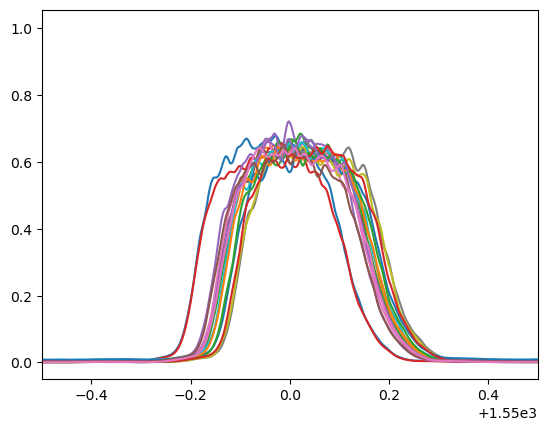

In [ ]:
sensor_dataframes['F1']
x=sensor_dataframes['F1']['Wavelength [nm]']
y=sensor_dataframes['F1'].drop(columns='Wavelength [nm]')
plt.plot(x,y);
plt.xlim(1549.5,1550.5);

In [2]:
import numpy as np
from scipy.signal import find_peaks
from scipy.interpolate import interp1d

def find_peak_half_power_wavelengths(wavelength, power, sensor_name, min_peak_height=0.1, min_peak_distance=50):
    """
    Find peaks in the power spectrum and calculate the wavelengths at half-power for each peak.
    
    Parameters:
    - wavelength: array of wavelength values
    - power: array of power values (normalized)
    - sensor_name: name of the sensor (for determining expected number of peaks)
    - min_peak_height: minimum normalized power for peak detection (default 0.1)
    - min_peak_distance: minimum distance between peaks in data points (default 50)
    
    Returns:
    - Dictionary with peak information including half-power wavelengths
    """
    
    # Find peaks in the spectrum
    peaks, properties = find_peaks(power, height=min_peak_height, distance=min_peak_distance)
    
    # Determine expected number of peaks based on sensor name
    sensor_num = int(sensor_name[1:])  # Extract number from F1, F2, etc.
    expected_peaks = 4 if sensor_num % 2 == 1 else 3  # Odd sensors: 4 peaks, Even sensors: 3 peaks
    
    # print(f"\n{sensor_name}: Found {len(peaks)} peaks (expected {expected_peaks})")
    
    peak_info = []
    
    for i, peak_idx in enumerate(peaks):
        peak_wavelength = wavelength[peak_idx]
        peak_power = power[peak_idx]
        half_power = peak_power / 2
        
        # Find half-power points on left and right sides of peak
        # Left side (shorter wavelengths)
        left_half_wl = None
        for j in range(peak_idx, -1, -1):
            if power[j] <= half_power:
                # Interpolate for more precise wavelength
                if j < peak_idx - 1:
                    left_half_wl = np.interp(half_power, 
                                            [power[j], power[j+1]], 
                                            [wavelength[j], wavelength[j+1]])
                else:
                    left_half_wl = wavelength[j]
                break
        
        # Right side (longer wavelengths)
        right_half_wl = None
        for j in range(peak_idx, len(power)):
            if power[j] <= half_power:
                # Interpolate for more precise wavelength
                if j > peak_idx + 1:
                    right_half_wl = np.interp(half_power, 
                                             [power[j-1], power[j]], 
                                             [wavelength[j-1], wavelength[j]])
                else:
                    right_half_wl = wavelength[j]
                break
        
        # Calculate FWHM (Full Width at Half Maximum)
        fwhm = None
        if left_half_wl is not None and right_half_wl is not None:
            fwhm = abs(right_half_wl - left_half_wl)  # Use abs() to handle descending wavelength
        
        peak_data = {
            'peak_number': i + 1,
            'peak_wavelength': peak_wavelength,
            'peak_power': peak_power,
            'half_power': half_power,
            'left_half_power_wl': left_half_wl,
            'right_half_power_wl': right_half_wl,
            'fwhm': fwhm
        }
        
        peak_info.append(peak_data)
        
        left_str = f"{left_half_wl:.2f}" if left_half_wl is not None else "N/A"
        right_str = f"{right_half_wl:.2f}" if right_half_wl is not None else "N/A"
        fwhm_str = f"{fwhm:.4f}" if fwhm is not None else "N/A"
        
        # print(f"  Peak {i+1}: λ={peak_wavelength:.2f} nm, "
        #       f"Left HP={left_str} nm, "
        #       f"Right HP={right_str} nm, "
        #       f"FWHM={fwhm_str} nm")
    
    return {
        'sensor_name': sensor_name,
        'peaks': peak_info,
        'wavelength': wavelength,
        'power': power,
        'peak_indices': peaks
    }

# # Test with F1 sensor, D1 column
# sensor_name = 'F1'
# day_column = 'D1'

# wavelength = sensor_dataframes[sensor_name]['Wavelength [nm]'].values
# power = sensor_dataframes[sensor_name][day_column].values

# # Use higher threshold and larger distance to find main peaks
# result = find_peak_half_power_wavelengths(wavelength, power, sensor_name, 
#                                          min_peak_height=0.3, min_peak_distance=100)

In [3]:
def plot_peaks_with_half_power(result_dict, title=None):

    wavelength = result_dict['wavelength']
    power = result_dict['power']
    peaks = result_dict['peaks']
    peak_indices = result_dict['peak_indices']
    
    plt.figure(figsize=(12, 6))
    
    # Plot the spectrum
    plt.plot(wavelength, power, 'b-', linewidth=1.5, label='Spectrum')
    
    # Mark peaks
    plt.plot(wavelength[peak_indices], power[peak_indices], 'ro', 
             markersize=10, label='Peaks')
    
    # Mark half-power points and draw FWHM lines
    colors = ['green', 'orange', 'purple', 'brown']
    for i, peak in enumerate(peaks):
        color = colors[i % len(colors)]
        
        # Mark half-power points
        if peak['left_half_power_wl'] is not None:
            plt.plot(peak['left_half_power_wl'], peak['half_power'], 
                    'x', color=color, markersize=10, markeredgewidth=3)
        
        if peak['right_half_power_wl'] is not None:
            plt.plot(peak['right_half_power_wl'], peak['half_power'], 
                    'x', color=color, markersize=10, markeredgewidth=3)
        
        # Draw horizontal line at half-power
        if peak['left_half_power_wl'] is not None and peak['right_half_power_wl'] is not None:
            plt.hlines(peak['half_power'], 
                      peak['left_half_power_wl'], 
                      peak['right_half_power_wl'],
                      colors=color, linestyles='dashed', linewidth=2,
                      label=f"Peak {i+1} FWHM={peak['fwhm']:.4f} nm")
    
    plt.xlabel('Wavelength [nm]', fontsize=12)
    plt.ylabel('Normalized Power', fontsize=12)
    if title:
        plt.title(title, fontsize=14)
    else:
        plt.title(f"{result_dict['sensor_name']} - Peak Analysis", fontsize=14)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# # Plot the result
# plot_peaks_with_half_power(result, title=f"{sensor_name} - {day_column} Peak Analysis")

In [4]:
def analyze_all_days_for_sensor(sensor_name, sensor_df, min_peak_height=0.3, min_peak_distance=100):
    wavelength = sensor_df['Wavelength [nm]'].values
    day_columns = [col for col in sensor_df.columns if col != 'Wavelength [nm]']
    
    # Storage for results
    all_results = {}
    
    # Determine expected number of peaks
    sensor_num = int(sensor_name[1:])
    expected_peaks = 4 if sensor_num % 2 == 1 else 3
    
    # print(f"\n{'='*70}")
    # print(f"Analyzing {sensor_name} - Expected {expected_peaks} peaks")
    # print(f"{'='*70}")
    
    for day in day_columns:
        power = sensor_df[day].values
        result = find_peak_half_power_wavelengths(wavelength, power, sensor_name, 
                                                  min_peak_height=min_peak_height, 
                                                  min_peak_distance=min_peak_distance)
        all_results[day] = result
    
    return all_results

def plot_half_power_wavelength_tracking(all_results, sensor_name):
    """
    Plot how the left and right half-power wavelengths change across different days.
    """
    # Sort days numerically by extracting the day number
    days = sorted(all_results.keys(), 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    # Determine number of peaks from first day
    num_peaks = len(all_results[days[0]]['peaks'])
    
    fig, axes = plt.subplots(num_peaks, 1, figsize=(14, 4*num_peaks))
    
    if num_peaks == 1:
        axes = [axes]
    
    for peak_idx in range(num_peaks):
        ax = axes[peak_idx]
        
        # Collect data for this peak across all days
        peak_wavelengths = []
        left_hp_wavelengths = []
        right_hp_wavelengths = []
        fwhm_values = []
        
        for day in days:
            peaks = all_results[day]['peaks']
            if peak_idx < len(peaks):
                peak = peaks[peak_idx]
                peak_wavelengths.append(peak['peak_wavelength'])
                left_hp_wavelengths.append(peak['left_half_power_wl'])
                right_hp_wavelengths.append(peak['right_half_power_wl'])
                fwhm_values.append(peak['fwhm'])
            else:
                peak_wavelengths.append(None)
                left_hp_wavelengths.append(None)
                right_hp_wavelengths.append(None)
                fwhm_values.append(None)
        
        # Plot
        x = range(len(days))
        # ax.plot(x, peak_wavelengths, 'ro-', linewidth=2, markersize=8, label='Peak Wavelength')
        ax.plot(x, left_hp_wavelengths, 'bs-', linewidth=2, markersize=6, label='Left Half-Power')
        # ax.plot(x, right_hp_wavelengths, 'g^-', linewidth=2, markersize=6, label='Right Half-Power')
        
        ax.set_xlabel('Day', fontsize=11)
        ax.set_ylabel('Wavelength [nm]', fontsize=11)
        ax.set_title(f'{sensor_name} - Peak {peak_idx + 1} Tracking', fontsize=12, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(days, rotation=45, ha='right')
        ax.legend(loc='best')
        ax.grid(True, alpha=0.3)
        
        # Add FWHM as text
        # ax2 = ax.twinx()
        # ax2.plot(x, fwhm_values, 'mo--', linewidth=1.5, markersize=5, alpha=0.6, label='FWHM')
        # ax2.set_ylabel('FWHM [nm]', fontsize=11, color='m')
        # ax2.tick_params(axis='y', labelcolor='m')
        # ax2.legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()


In [5]:
def vessel_plotter(allResults1, sensorName1, allResults2, sensorName2, colors1=None, colors2=None):
    """
    Plot vessel data for two sensors.
    
    Parameters:
    -----------
    allResults1 : dict
        Results for sensor 1
    sensorName1 : str
        Name of sensor 1
    allResults2 : dict
        Results for sensor 2
    sensorName2 : str
        Name of sensor 2
    colors1 : list of str, optional
        List of colors for sensor 1 traces ordered from longest to shortest wavelength.
        Example: ['blue', 'yellow', 'green', 'red']
        If None, matplotlib default colors will be used.
    colors2 : list of str, optional
        List of colors for sensor 2 traces ordered from longest to shortest wavelength.
        Example: ['blue', 'yellow', 'green', 'red']
        If None, matplotlib default colors will be used.
    """
    days = sorted(allResults1.keys(), key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    num_peaks1 = len(allResults1[days[0]]['peaks'])
    num_peaks2 = len(allResults2[days[0]]['peaks'])
    
    # Collect all data to determine global y-axis limits
    all_shifts = []
    
    # Get baseline wavelengths for sensor 1 and create sorted indices
    baselines1 = []
    for peak_idx in range(num_peaks1):
        peaks = allResults1[days[0]]['peaks']
        if peak_idx < len(peaks):
            baselines1.append((peak_idx, peaks[peak_idx]['peak_wavelength']))
    # Sort by wavelength (longest first)
    sorted_indices1 = [idx for idx, wl in sorted(baselines1, key=lambda x: x[1], reverse=True)]
    
    # Plot sensor 1 peaks
    for color_idx, peak_idx in enumerate(sorted_indices1):
        peakWave = []
        for day in days:
            peaks = allResults1[day]['peaks']
            if peak_idx < len(peaks):
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakWave.append(None)
        
        # Normalize: subtract Day 1 wavelength to get shift
        baseline = peakWave[0] if peakWave[0] is not None else 0
        peakWave_shift = [w - baseline if w is not None else None for w in peakWave]
        all_shifts.extend([s for s in peakWave_shift if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 'label': f'{baseline:.2f} nm'}
        if colors1 is not None and color_idx < len(colors1):
            plot_kwargs['color'] = colors1[color_idx]
        ax[0].plot(x, peakWave_shift, 'o-', **plot_kwargs)
    
    # ax[0].set_xlabel('Day', fontsize=11)
    ax[0].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[0].set_title(f'{sensorName1}', fontsize=12, fontweight='bold')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Get baseline wavelengths for sensor 2 and create sorted indices
    baselines2 = []
    for peak_idx in range(num_peaks2):
        peaks = allResults2[days[0]]['peaks']
        if peak_idx < len(peaks):
            baselines2.append((peak_idx, peaks[peak_idx]['peak_wavelength']))
    # Sort by wavelength (longest first)
    sorted_indices2 = [idx for idx, wl in sorted(baselines2, key=lambda x: x[1], reverse=True)]
    
    # Plot sensor 2 peaks
    for color_idx, peak_idx in enumerate(sorted_indices2):
        peakWave = []
        for day in days:
            peaks = allResults2[day]['peaks']
            if peak_idx < len(peaks):
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakWave.append(None)
        
        # Normalize: subtract Day 1 wavelength to get shift
        baseline = peakWave[0] if peakWave[0] is not None else 0
        peakWave_shift = [w - baseline if w is not None else None for w in peakWave]
        all_shifts.extend([s for s in peakWave_shift if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 'label': f'{baseline:.2f} nm'}
        if colors2 is not None and color_idx < len(colors2):
            plot_kwargs['color'] = colors2[color_idx]
        ax[1].plot(x, peakWave_shift, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[1].set_title(f'{sensorName2}', fontsize=12, fontweight='bold')
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Set consistent y-axis limits for both subplots
    if all_shifts:
        y_min = min(all_shifts)
        y_max = max(all_shifts)
        y_margin = (y_max - y_min) * 0.1  # Add 10% margin
        ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
        ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

In [6]:
def vessel_plotter_with_reference(allResults1, sensorName1, allResults2, sensorName2, reference_wavelength, colors1=None, colors2=None):
    """
    Plot vessel data with a reference wavelength trace removed from all others.
    The reference is taken from sensor 1 only and applied to both sensors.
    The reference trace itself is NOT plotted.
    
    Parameters:
    -----------
    allResults1 : dict
        Results for sensor 1 (odd-numbered sensor, e.g., F1)
    sensorName1 : str
        Name of sensor 1
    allResults2 : dict
        Results for sensor 2 (even-numbered sensor, e.g., F2)
    sensorName2 : str
        Name of sensor 2
    reference_wavelength : float
        The wavelength (e.g., 1545) from sensor 1 to use as reference. 
        The peak closest to this wavelength in sensor 1 will be found and 
        its shift will be subtracted from all traces in BOTH sensors.
        This reference trace will NOT be displayed on the plot.
    colors1 : list of str, optional
        List of colors for sensor 1 traces ordered from longest to shortest wavelength.
        Example: ['blue', 'yellow', 'green', 'red']
        If None, matplotlib default colors will be used.
    colors2 : list of str, optional
        List of colors for sensor 2 traces ordered from longest to shortest wavelength.
        Example: ['blue', 'yellow', 'green', 'red']
        If None, matplotlib default colors will be used.
    """
    days = sorted(allResults1.keys(), key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    num_peaks1 = len(allResults1[days[0]]['peaks'])
    num_peaks2 = len(allResults2[days[0]]['peaks'])
    
    # Collect all data to determine global y-axis limits
    all_corrected = []
    
    # Helper function to find the peak closest to reference wavelength
    def find_reference_peak_idx(allResults, days, reference_wavelength):
        first_day_peaks = allResults[days[0]]['peaks']
        min_diff = float('inf')
        ref_idx = 0
        for idx, peak in enumerate(first_day_peaks):
            diff = abs(peak['peak_wavelength'] - reference_wavelength)
            if diff < min_diff:
                min_diff = diff
                ref_idx = idx
        return ref_idx
    
    # Find reference peak index ONLY from sensor 1 (the odd-numbered sensor)
    ref_idx1 = find_reference_peak_idx(allResults1, days, reference_wavelength)
    
    # Get reference trace shifts from sensor 1
    ref_peakWave1 = []
    for day in days:
        peaks = allResults1[day]['peaks']
        if ref_idx1 < len(peaks):
            ref_peakWave1.append(peaks[ref_idx1]['peak_wavelength'])
        else:
            ref_peakWave1.append(None)
    
    baseline_ref1 = ref_peakWave1[0] if ref_peakWave1[0] is not None else 0
    ref_shift1 = [w - baseline_ref1 if w is not None else None for w in ref_peakWave1]
    
    # Get baseline wavelengths for sensor 1 and create sorted indices
    baselines1 = []
    for peak_idx in range(num_peaks1):
        peaks = allResults1[days[0]]['peaks']
        if peak_idx < len(peaks):
            baselines1.append((peak_idx, peaks[peak_idx]['peak_wavelength']))
    # Sort by wavelength (longest first)
    sorted_indices1 = [idx for idx, wl in sorted(baselines1, key=lambda x: x[1], reverse=True)]
    
    # Plot sensor 1 peaks (SKIP the reference peak)
    plotted_color_idx = 0
    for color_idx, peak_idx in enumerate(sorted_indices1):
        # Skip plotting the reference peak
        if peak_idx == ref_idx1:
            continue
            
        peakWave = []
        for day in days:
            peaks = allResults1[day]['peaks']
            if peak_idx < len(peaks):
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakWave.append(None)
        
        # Normalize: subtract Day 1 wavelength to get shift
        baseline = peakWave[0] if peakWave[0] is not None else 0
        peakWave_shift = [w - baseline if w is not None else None for w in peakWave]
        
        # Subtract reference shift from this trace
        peakWave_corrected = []
        for i in range(len(peakWave_shift)):
            if peakWave_shift[i] is not None and ref_shift1[i] is not None:
                peakWave_corrected.append(peakWave_shift[i] - ref_shift1[i])
            else:
                peakWave_corrected.append(None)
        
        all_corrected.extend([s for s in peakWave_corrected if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 'label': f'{baseline:.2f} nm'}
        if colors1 is not None and plotted_color_idx < len(colors1):
            plot_kwargs['color'] = colors1[plotted_color_idx]
        ax[0].plot(x, peakWave_corrected, 'o-', **plot_kwargs)
        plotted_color_idx += 1
    
    ax[0].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[0].set_title(f'{sensorName1} (Reference removed)', fontsize=12, fontweight='bold')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Get baseline wavelengths for sensor 2 and create sorted indices
    baselines2 = []
    for peak_idx in range(num_peaks2):
        peaks = allResults2[days[0]]['peaks']
        if peak_idx < len(peaks):
            baselines2.append((peak_idx, peaks[peak_idx]['peak_wavelength']))
    # Sort by wavelength (longest first)
    sorted_indices2 = [idx for idx, wl in sorted(baselines2, key=lambda x: x[1], reverse=True)]
    
    # Plot sensor 2 peaks (using the SAME reference shift from sensor 1)
    for color_idx, peak_idx in enumerate(sorted_indices2):
        peakWave = []
        for day in days:
            peaks = allResults2[day]['peaks']
            if peak_idx < len(peaks):
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakWave.append(None)
        
        # Normalize: subtract Day 1 wavelength to get shift
        baseline = peakWave[0] if peakWave[0] is not None else 0
        peakWave_shift = [w - baseline if w is not None else None for w in peakWave]
        
        # Subtract the SAME reference shift from sensor 1
        peakWave_corrected = []
        for i in range(len(peakWave_shift)):
            if peakWave_shift[i] is not None and ref_shift1[i] is not None:
                peakWave_corrected.append(peakWave_shift[i] - ref_shift1[i])
            else:
                peakWave_corrected.append(None)
        
        all_corrected.extend([s for s in peakWave_corrected if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 'label': f'{baseline:.2f} nm'}
        if colors2 is not None and color_idx < len(colors2):
            plot_kwargs['color'] = colors2[color_idx]
        ax[1].plot(x, peakWave_corrected, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[1].set_title(f'{sensorName2} (Reference removed)', fontsize=12, fontweight='bold')
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Set consistent y-axis limits for both subplots
    if all_corrected:
        y_min = min(all_corrected)
        y_max = max(all_corrected)
        y_margin = (y_max - y_min) * 0.1  # Add 10% margin
        ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
        ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

In [7]:
# all_results_f1 = analyze_all_days_for_sensor('F1', sensor_dataframes['F1'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f2 = analyze_all_days_for_sensor('F2', sensor_dataframes['F2'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f3 = analyze_all_days_for_sensor('F3', sensor_dataframes['F3'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f4 = analyze_all_days_for_sensor('F4', sensor_dataframes['F4'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f5 = analyze_all_days_for_sensor('F5', sensor_dataframes['F5'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f6 = analyze_all_days_for_sensor('F6', sensor_dataframes['F6'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f7 = analyze_all_days_for_sensor('F7', sensor_dataframes['F7'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f8 = analyze_all_days_for_sensor('F8', sensor_dataframes['F8'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f9 = analyze_all_days_for_sensor('F9', sensor_dataframes['F9'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f10 = analyze_all_days_for_sensor('F10', sensor_dataframes['F10'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f11 = analyze_all_days_for_sensor('F11', sensor_dataframes['F11'], min_peak_height=0.3, min_peak_distance=100)
# all_results_f12 = analyze_all_days_for_sensor('F12', sensor_dataframes['F12'], min_peak_height=0.3, min_peak_distance=100)

# #                                                                Ref - red | left - blue | right - green | center - yellow

# vessel_plotter(all_results_f1, 'F1', all_results_f2, 'F2',colors1=['green','orange','blue','red'],colors2=['green','orange','blue'])
# vessel_plotter(all_results_f3, 'F3', all_results_f4, 'F4',colors1=['green','orange','red','blue'],colors2=['green','orange','blue'])
# vessel_plotter(all_results_f5, 'F5', all_results_f6, 'F6',colors1=['green','orange','red','blue'],colors2=['green','orange','blue'])
# vessel_plotter(all_results_f7, 'F7', all_results_f8, 'F8',colors1=['green','red','orange','blue'],colors2=['orange','green','blue'])
# vessel_plotter(all_results_f9, 'F9', all_results_f10, 'F10',colors1=['blue','green','orange','red'],colors2=['orange','blue','green'])
# vessel_plotter(all_results_f11, 'F11', all_results_f12, 'F12',colors1=['red','green','orange','blue'],colors2=['green','orange','blue'])

In [8]:
# vessel_plotter_with_reference(all_results_f1, 'F1', all_results_f2, 'F2',colors1=['green','orange','blue'],colors2=['green','orange','blue'],reference_wavelength=1545)
# vessel_plotter_with_reference(all_results_f3, 'F3', all_results_f4, 'F4',colors1=['green','orange','blue'],colors2=['green','orange','blue'],reference_wavelength=1547)
# vessel_plotter_with_reference(all_results_f5, 'F5', all_results_f6, 'F6',colors1=['green','orange','blue'],colors2=['green','orange','blue'],reference_wavelength=1550)
# vessel_plotter_with_reference(all_results_f7, 'F7', all_results_f8, 'F8',colors1=['green','orange','blue'],colors2=['orange','green','blue'],reference_wavelength=1550)
# vessel_plotter_with_reference(all_results_f9, 'F9', all_results_f10, 'F10',colors1=['blue','green','orange'],colors2=['orange','blue','green'],reference_wavelength=1545)
# vessel_plotter_with_reference(all_results_f11, 'F11', all_results_f12, 'F12',colors1=['green','orange','blue'],colors2=['green','orange','blue'],reference_wavelength=1553)

In [9]:
def power_tracker(allResults1, sensorName1, allResults2, sensorName2, 
                  wavelengths1=None, wavelengths2=None, colors1=None, colors2=None):
    """
    Track the normalized power changes over time for specific wavelength peaks.
    
    Parameters:
    -----------
    allResults1 : dict
        Results for sensor 1
    sensorName1 : str
        Name of sensor 1
    allResults2 : dict
        Results for sensor 2
    sensorName2 : str
        Name of sensor 2
    wavelengths1 : list of float, optional
        List of wavelengths to track for sensor 1. If None, tracks all peaks.
        Example: [1545.5, 1548.2, 1550.1] for 3 peaks
        The function will find the closest peak to each specified wavelength.
    wavelengths2 : list of float, optional
        List of wavelengths to track for sensor 2. If None, tracks all peaks.
    colors1 : list of str, optional
        List of colors for sensor 1 traces (one per wavelength specified).
        If None, matplotlib default colors will be used.
    colors2 : list of str, optional
        List of colors for sensor 2 traces (one per wavelength specified).
        If None, matplotlib default colors will be used.
    """
    days = sorted(allResults1.keys(), key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_power_changes = []
    
    # Helper function to find peak index closest to target wavelength
    def find_peak_by_wavelength(allResults, days, target_wavelength):
        first_day_peaks = allResults[days[0]]['peaks']
        min_diff = float('inf')
        best_idx = 0
        for idx, peak in enumerate(first_day_peaks):
            diff = abs(peak['peak_wavelength'] - target_wavelength)
            if diff < min_diff:
                min_diff = diff
                best_idx = idx
        return best_idx
    
    # Process sensor 1
    num_peaks1 = len(allResults1[days[0]]['peaks'])
    
    # Determine which peaks to plot for sensor 1
    if wavelengths1 is not None:
        # Find peak indices for specified wavelengths
        peak_indices1 = [find_peak_by_wavelength(allResults1, days, wl) for wl in wavelengths1]
    else:
        # Plot all peaks
        peak_indices1 = list(range(num_peaks1))
    
    # Plot sensor 1 peaks
    for color_idx, peak_idx in enumerate(peak_indices1):
        peakPower = []
        peakWave = []
        
        for day in days:
            peaks = allResults1[day]['peaks']
            if peak_idx < len(peaks):
                peakPower.append(peaks[peak_idx]['peak_power'])
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakPower.append(None)
                peakWave.append(None)
        
        # Calculate power change relative to Day 1
        baseline_power = peakPower[0] if peakPower[0] is not None else 1.0
        baseline_wavelength = peakWave[0] if peakWave[0] is not None else 0
        power_change = [((p - baseline_power) / baseline_power * 100) if p is not None else None 
                       for p in peakPower]
        all_power_changes.extend([c for c in power_change if c is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline_wavelength:.2f} nm'}
        if colors1 is not None and color_idx < len(colors1):
            plot_kwargs['color'] = colors1[color_idx]
        ax[0].plot(x, power_change, 'o-', **plot_kwargs)
    
    ax[0].set_ylabel('Power Change [%]', fontsize=11)
    ax[0].set_title(f'{sensorName1} - Normalized Power Change', fontsize=12, fontweight='bold')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Process sensor 2
    num_peaks2 = len(allResults2[days[0]]['peaks'])
    
    # Determine which peaks to plot for sensor 2
    if wavelengths2 is not None:
        # Find peak indices for specified wavelengths
        peak_indices2 = [find_peak_by_wavelength(allResults2, days, wl) for wl in wavelengths2]
    else:
        # Plot all peaks
        peak_indices2 = list(range(num_peaks2))
    
    # Plot sensor 2 peaks
    for color_idx, peak_idx in enumerate(peak_indices2):
        peakPower = []
        peakWave = []
        
        for day in days:
            peaks = allResults2[day]['peaks']
            if peak_idx < len(peaks):
                peakPower.append(peaks[peak_idx]['peak_power'])
                peakWave.append(peaks[peak_idx]['peak_wavelength'])
            else:
                peakPower.append(None)
                peakWave.append(None)
        
        # Calculate power change relative to Day 1
        baseline_power = peakPower[0] if peakPower[0] is not None else 1.0
        baseline_wavelength = peakWave[0] if peakWave[0] is not None else 0
        power_change = [((p - baseline_power) / baseline_power * 100) if p is not None else None 
                       for p in peakPower]
        all_power_changes.extend([c for c in power_change if c is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline_wavelength:.2f} nm'}
        if colors2 is not None and color_idx < len(colors2):
            plot_kwargs['color'] = colors2[color_idx]
        ax[1].plot(x, power_change, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Power Change [%]', fontsize=11)
    ax[1].set_title(f'{sensorName2} - Normalized Power Change', fontsize=12, fontweight='bold')
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Set consistent y-axis limits for both subplots
    if all_power_changes:
        y_min = min(all_power_changes)
        y_max = max(all_power_changes)
        y_margin = (y_max - y_min) * 0.1  # Add 10% margin
        ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
        ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

In [10]:
def power_tracker_from_dataframes(df1, sensorName1, df2, sensorName2, 
                                  wavelengths1=None, wavelengths2=None, 
                                  colors1=None, colors2=None, tolerance=0.1):
    """
    Track the normalized power changes over time for specific wavelengths using raw dataframes.
    
    Parameters:
    -----------
    df1 : DataFrame
        Sensor dataframe 1 (e.g., sensor_dataframes['F1'])
    sensorName1 : str
        Name of sensor 1
    df2 : DataFrame
        Sensor dataframe 2 (e.g., sensor_dataframes['F2'])
    sensorName2 : str
        Name of sensor 2
    wavelengths1 : list of float, optional
        List of exact wavelengths to track for sensor 1. If None, you must specify them.
        Example: [1545.95, 1549.825, 1552.32, 1553.225]
        The function will find the closest wavelength in the dataframe within tolerance.
    wavelengths2 : list of float, optional
        List of exact wavelengths to track for sensor 2.
    colors1 : list of str, optional
        List of colors for sensor 1 traces (one per wavelength specified).
    colors2 : list of str, optional
        List of colors for sensor 2 traces (one per wavelength specified).
    tolerance : float, optional
        Maximum difference (in nm) between specified and actual wavelength (default: 0.1)
    """
    # Get wavelength column and day columns
    wavelength_col1 = df1['Wavelength [nm]'].values
    wavelength_col2 = df2['Wavelength [nm]'].values
    
    day_columns1 = [col for col in df1.columns if col != 'Wavelength [nm]']
    day_columns2 = [col for col in df2.columns if col != 'Wavelength [nm]']
    
    # Sort days
    days = sorted(day_columns1, 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_power_changes = []
    
    # Helper function to find wavelength index
    def find_wavelength_idx(wavelength_array, target_wl, tolerance):
        diffs = np.abs(wavelength_array - target_wl)
        min_idx = np.argmin(diffs)
        if diffs[min_idx] <= tolerance:
            return min_idx, wavelength_array[min_idx]
        else:
            return None, None
    
    # Process sensor 1
    if wavelengths1 is None:
        raise ValueError("wavelengths1 must be specified (list of wavelengths to track)")
    
    for color_idx, target_wl in enumerate(wavelengths1):
        wl_idx, actual_wl = find_wavelength_idx(wavelength_col1, target_wl, tolerance)
        
        if wl_idx is None:
            print(f"Warning: Could not find wavelength close to {target_wl} nm in {sensorName1}")
            continue
        
        # Extract power values for this wavelength across all days
        power_values = []
        for day in days:
            if day in df1.columns:
                power_values.append(df1[day].iloc[wl_idx])
            else:
                power_values.append(None)
        
        # Calculate power change relative to Day 1
        baseline_power = power_values[0] if power_values[0] is not None else 1.0
        power_change = [((p - baseline_power) / baseline_power * 100) if p is not None else None 
                       for p in power_values]
        all_power_changes.extend([c for c in power_change if c is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{actual_wl:.2f} nm'}
        if colors1 is not None and color_idx < len(colors1):
            plot_kwargs['color'] = colors1[color_idx]
        ax[0].plot(x, power_change, 'o-', **plot_kwargs)
    
    ax[0].set_ylabel('Power Change [%]', fontsize=11)
    ax[0].set_title(f'{sensorName1} - Normalized Power Change', fontsize=12, fontweight='bold')
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Process sensor 2
    if wavelengths2 is None:
        raise ValueError("wavelengths2 must be specified (list of wavelengths to track)")
    
    for color_idx, target_wl in enumerate(wavelengths2):
        wl_idx, actual_wl = find_wavelength_idx(wavelength_col2, target_wl, tolerance)
        
        if wl_idx is None:
            print(f"Warning: Could not find wavelength close to {target_wl} nm in {sensorName2}")
            continue
        
        # Extract power values for this wavelength across all days
        power_values = []
        for day in days:
            if day in df2.columns:
                power_values.append(df2[day].iloc[wl_idx])
            else:
                power_values.append(None)
        
        # Calculate power change relative to Day 1
        baseline_power = power_values[0] if power_values[0] is not None else 1.0
        power_change = [((p - baseline_power) / baseline_power * 100) if p is not None else None 
                       for p in power_values]
        all_power_changes.extend([c for c in power_change if c is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{actual_wl:.2f} nm'}
        if colors2 is not None and color_idx < len(colors2):
            plot_kwargs['color'] = colors2[color_idx]
        ax[1].plot(x, power_change, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Power Change [%]', fontsize=11)
    ax[1].set_title(f'{sensorName2} - Normalized Power Change', fontsize=12, fontweight='bold')
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Set consistent y-axis limits for both subplots
    if all_power_changes:
        y_min = min(all_power_changes)
        y_max = max(all_power_changes)
        y_margin = (y_max - y_min) * 0.1  # Add 10% margin
        # ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
        # ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

### Power Tracker from Dataframes Examples

In [11]:
def power_level_wavelength_tracker(df1, sensorName1, df2, sensorName2, 
                                    power_level=0.6, colors1=None, colors2=None,
                                    num_crossings1=4, num_crossings2=3,
                                    ylim_min1=None,ylim_max1=None,
                                    ylim_min2=None,ylim_max2=None,
                                    vlines=None):
    """
    Track wavelength shifts at a specific normalized power level across all days.
    
    This function finds where the spectrum crosses a specified power threshold 
    (e.g., 0.6) and tracks how those wavelengths shift over time relative to Day 1.
    
    Parameters:
    -----------
    df1 : DataFrame
        Sensor dataframe 1 (e.g., sensor_dataframes['F1'])
    sensorName1 : str
        Name of sensor 1
    df2 : DataFrame
        Sensor dataframe 2 (e.g., sensor_dataframes['F2'])
    sensorName2 : str
        Name of sensor 2
    power_level : float, optional
        Normalized power level to track (default: 0.6)
        Must be between 0 and 1 since data is normalized.
    colors1 : list of str, optional
        List of colors for sensor 1 traces (one per crossing)
    colors2 : list of str, optional
        List of colors for sensor 2 traces (one per crossing)
    num_crossings1 : int, optional
        Expected number of power crossings for sensor 1 (default: 4 for odd sensors)
    num_crossings2 : int, optional
        Expected number of power crossings for sensor 2 (default: 3 for even sensors)
    vlines : list of int, optional
        List of day numbers (e.g., [0, 1, 3, 5]) to draw vertical lines at.
        Matches against the numeric (XX) portion of DXX labels.
    """
    # Get wavelength column and day columns
    wavelength_col1 = df1['Wavelength [nm]'].values
    wavelength_col2 = df2['Wavelength [nm]'].values
    
    day_columns = [col for col in df1.columns if col != 'Wavelength [nm]']
    
    # Sort days
    days = sorted(day_columns, 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_shifts = []
    
    def find_power_crossings(wavelength_array, power_array, target_power, num_expected):
        """
        Find wavelengths where the power crosses the target level.
        Returns wavelengths sorted from shortest to longest.
        """
        crossings = []
        
        # Find all points where power crosses the threshold
        for i in range(len(power_array) - 1):
            # Check if we cross the threshold between consecutive points
            if (power_array[i] <= target_power <= power_array[i+1]) or \
               (power_array[i] >= target_power >= power_array[i+1]):
                # Interpolate to find exact wavelength at threshold
                wl = np.interp(target_power, 
                              [power_array[i], power_array[i+1]], 
                              [wavelength_array[i], wavelength_array[i+1]])
                crossings.append(wl)
        
        # Sort crossings by wavelength
        crossings.sort()
        
        # If we have too many crossings, keep the most prominent ones
        # (those near peak centers, approximately evenly spaced)
        if len(crossings) > num_expected * 2:
            # Keep every other crossing (left side of peaks)
            crossings = crossings[::2]
        
        # Return the expected number of crossings
        if len(crossings) >= num_expected:
            # Select evenly spaced crossings
            step = len(crossings) / num_expected
            selected = [crossings[int(i * step)] for i in range(num_expected)]
            return selected
        else:
            return crossings
    
    # Process sensor 1
    baseline_wavelengths1 = []
    wavelength_data1 = {}  # Store wavelength values for each crossing across days
    
    # Get baseline wavelengths from Day 1
    power1_day1 = df1[days[0]].values
    baseline_wavelengths1 = find_power_crossings(wavelength_col1, power1_day1, 
                                                 power_level, num_crossings1)
    
    # Initialize storage for each crossing
    for idx in range(len(baseline_wavelengths1)):
        wavelength_data1[idx] = []
    
    # Track wavelengths across all days
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        
        # Match current crossings to baseline wavelengths
        for idx, baseline_wl in enumerate(baseline_wavelengths1):
            if idx < len(current_crossings):
                wavelength_data1[idx].append(current_crossings[idx])
            else:
                wavelength_data1[idx].append(None)
    
    # Plot sensor 1
    for idx in range(len(baseline_wavelengths1)):
        wavelengths = wavelength_data1[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        all_shifts.extend([s for s in shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors1 is not None and idx < len(colors1):
            plot_kwargs['color'] = colors1[idx]
        ax[0].plot(x, shifts, 'o-', **plot_kwargs)
    
    ax[0].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[0].set_title('Top')
    ax[0].set_ylim(ylim_min1,ylim_max1)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Process sensor 2
    baseline_wavelengths2 = []
    wavelength_data2 = {}
    
    # Get baseline wavelengths from Day 1
    power2_day1 = df2[days[0]].values
    baseline_wavelengths2 = find_power_crossings(wavelength_col2, power2_day1, 
                                                 power_level, num_crossings2)
    
    # Initialize storage for each crossing
    for idx in range(len(baseline_wavelengths2)):
        wavelength_data2[idx] = []
    
    # Track wavelengths across all days
    for day in days:
        power2 = df2[day].values
        current_crossings = find_power_crossings(wavelength_col2, power2, 
                                                 power_level, num_crossings2)
        
        # Match current crossings to baseline wavelengths
        for idx, baseline_wl in enumerate(baseline_wavelengths2):
            if idx < len(current_crossings):
                wavelength_data2[idx].append(current_crossings[idx])
            else:
                wavelength_data2[idx].append(None)
    
    # Plot sensor 2
    for idx in range(len(baseline_wavelengths2)):
        wavelengths = wavelength_data2[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        all_shifts.extend([s for s in shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors2 is not None and idx < len(colors2):
            plot_kwargs['color'] = colors2[idx]
        ax[1].plot(x, shifts, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[1].set_title('Bottom')
    ax[1].set_xticks(x)
    ax[1].set_ylim(ylim_min2,ylim_max2)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Draw vertical lines on specified days
    if vlines is not None:
        vline_str = [str(v).zfill(2) for v in vlines]
        for i, day_label in enumerate(days):
            day_num = day_label.replace('D', '').split('_')[0]
            if day_num in vline_str:
                ax[0].axvline(x=i, color='black', linestyle=':', linewidth=2.5, alpha=0.7)
                ax[1].axvline(x=i, color='black', linestyle=':', linewidth=2.5, alpha=0.7)
    
    # Set consistent y-axis limits for both subplots
    if all_shifts:
        y_min = min(all_shifts)
        y_max = max(all_shifts)
        y_margin = (y_max - y_min) * 0.1  # Add 10% margin
        # ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
        # ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

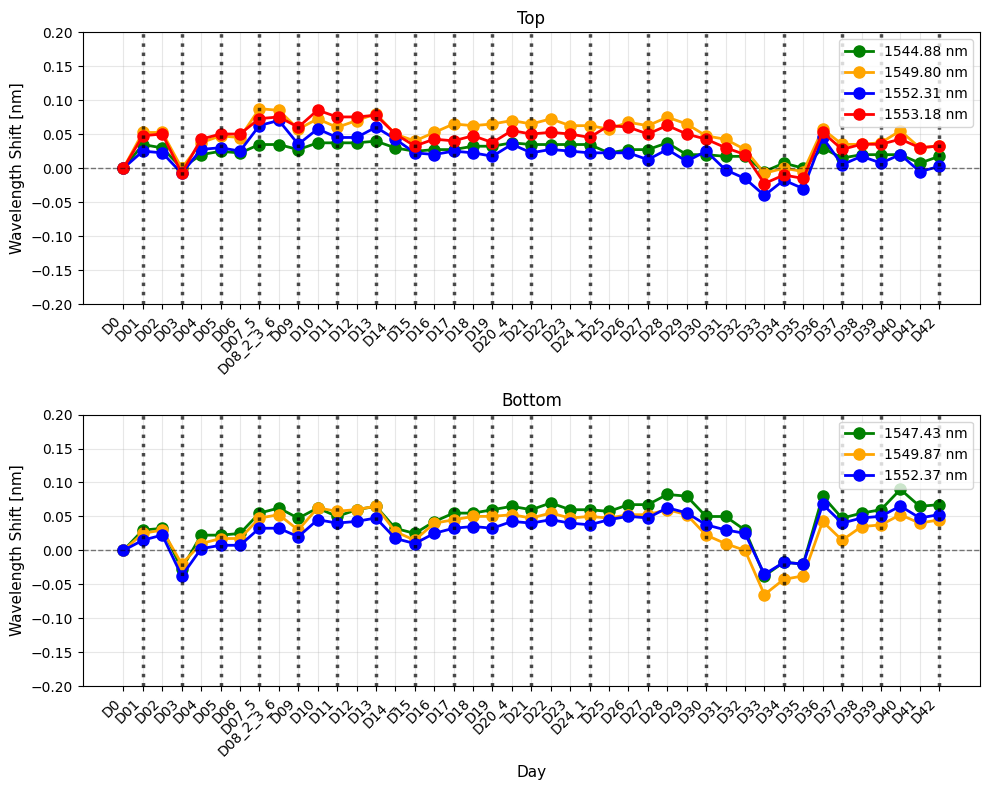

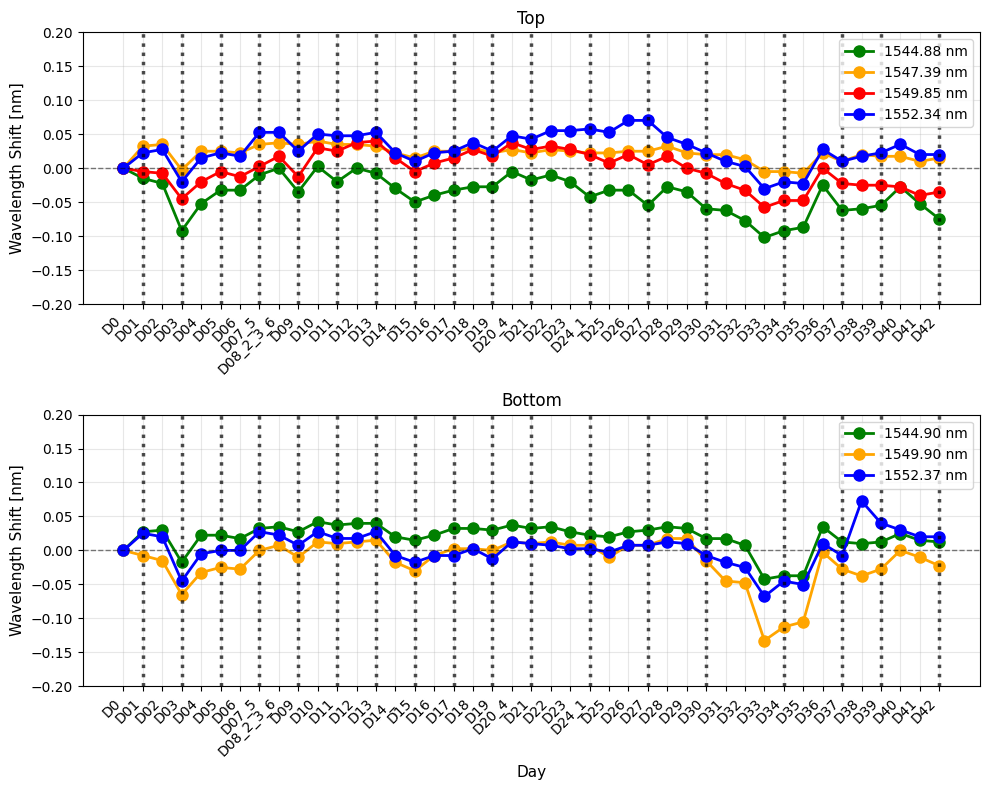

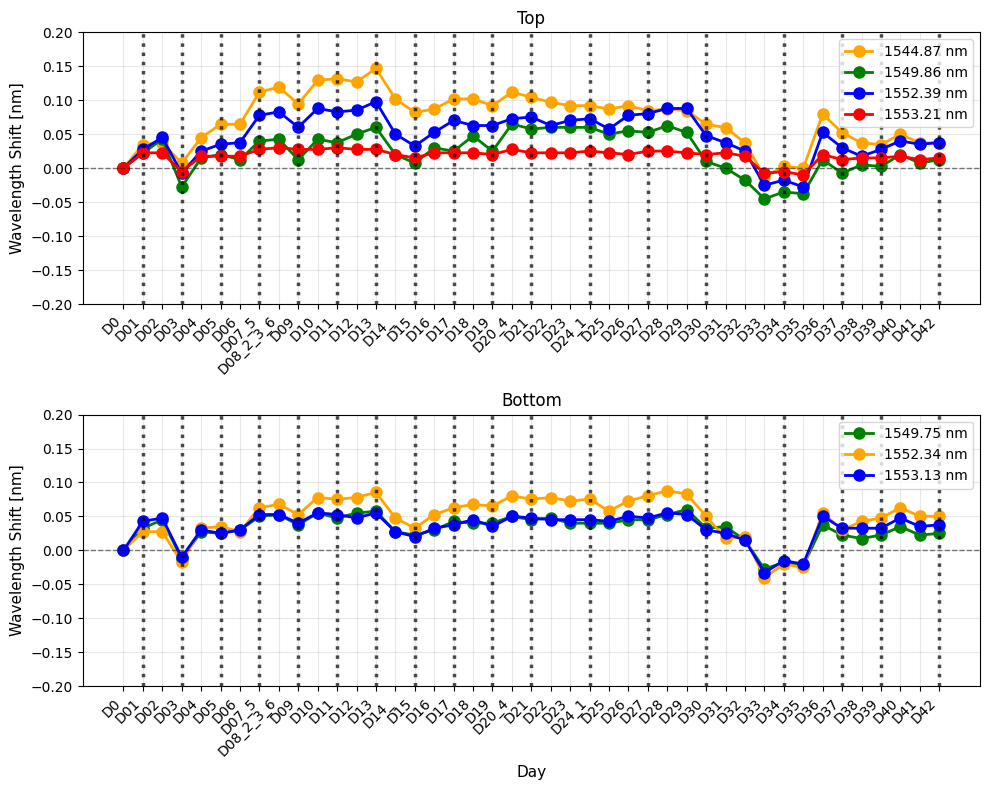

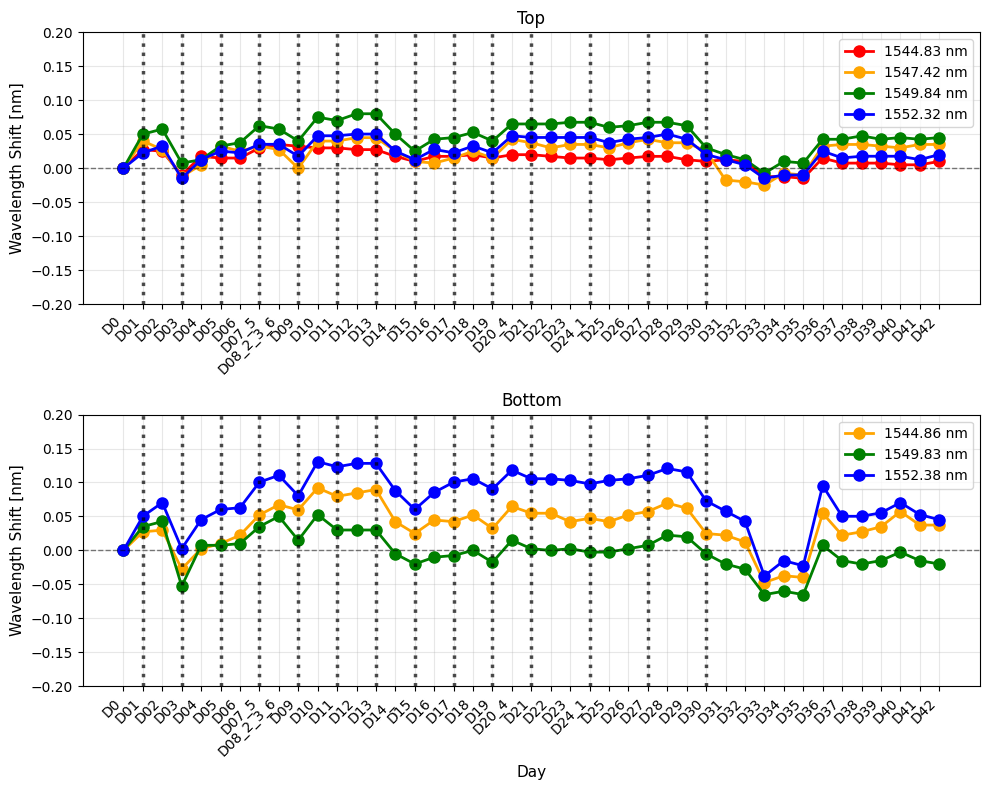

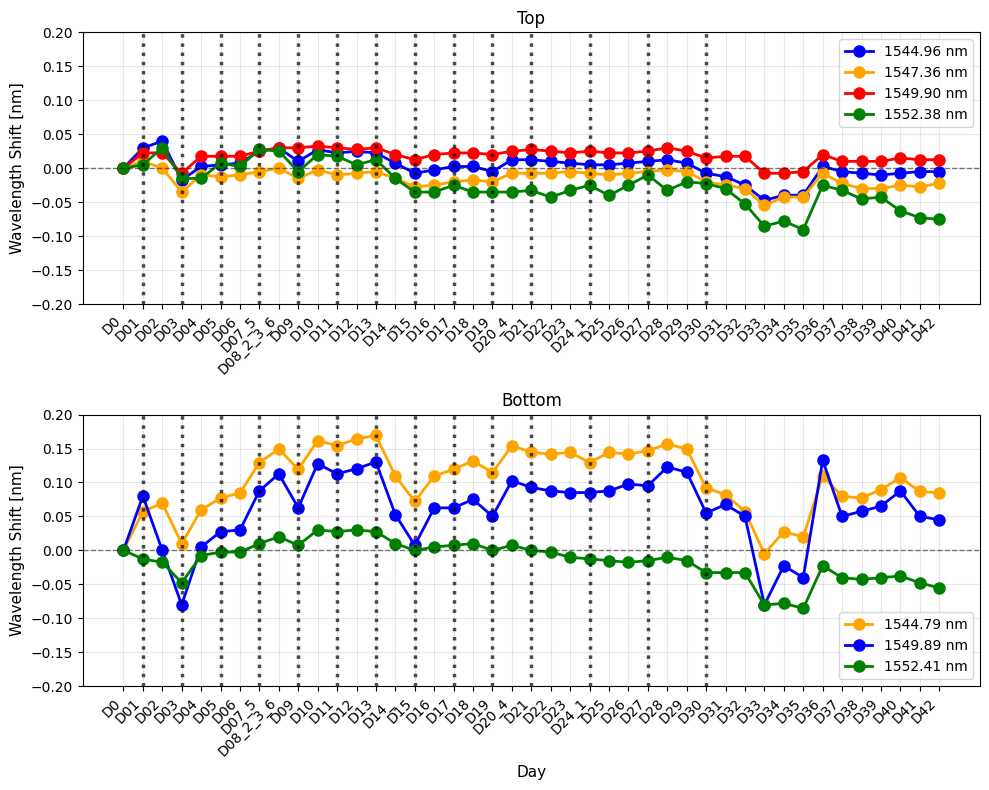

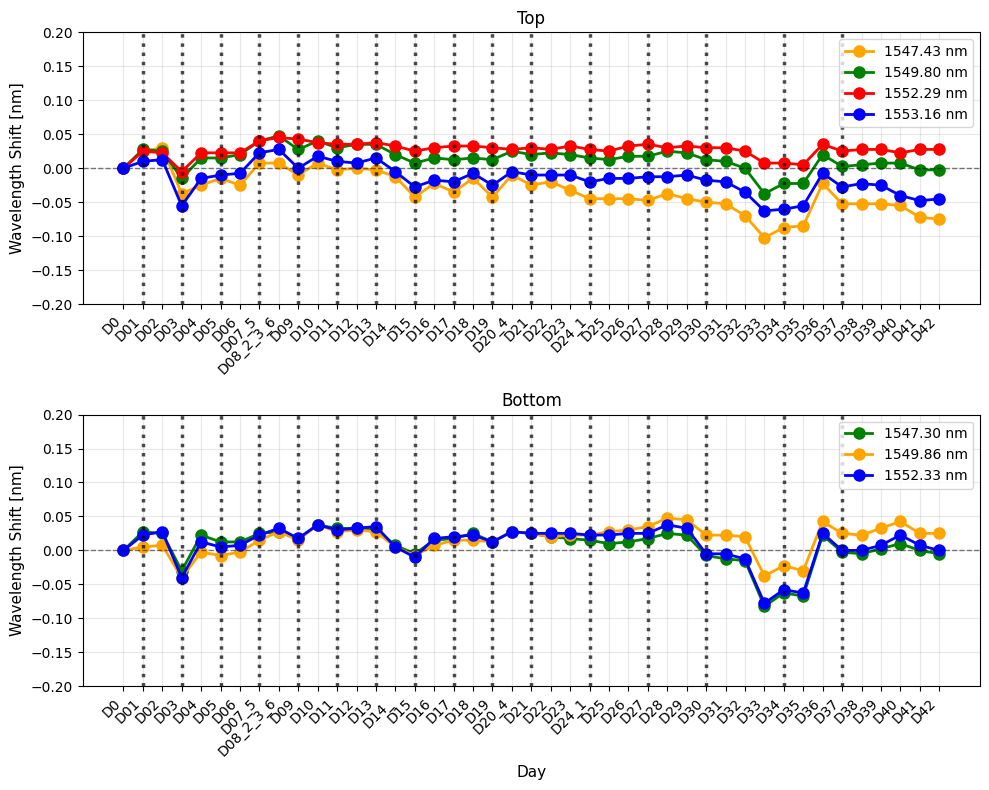

In [15]:
p_level=0.2
y_min=-0.2
y_max=0.2
waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30,34,37,39,42]

power_level_wavelength_tracker(
    sensor_dataframes['F1'], 'F1', 
    sensor_dataframes['F2'], 'F2',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green', 'orange', 'blue', 'red'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker(
    sensor_dataframes['F3'], 'F3', 
    sensor_dataframes['F4'], 'F4',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green', 'orange', 'red', 'blue'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker(
    sensor_dataframes['F5'], 'F5', 
    sensor_dataframes['F6'], 'F6',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['orange','green',  'blue', 'red'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)

waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30]
power_level_wavelength_tracker(
    sensor_dataframes['F7'], 'F7', 
    sensor_dataframes['F8'], 'F8',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['red','orange','green',   'blue'],
    colors2=['orange','green',  'blue'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker(
    sensor_dataframes['F9'], 'F9', 
    sensor_dataframes['F10'], 'F10',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['blue','orange','red','green'],
    colors2=['orange','blue','green'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)

waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30,34,37]
power_level_wavelength_tracker(
    sensor_dataframes['F11'], 'F11', 
    sensor_dataframes['F12'], 'F12',
    power_level=p_level-0.1,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['orange','green','red','blue'],
    colors2=['green','orange','blue'],
    ylim_min1=y_min,ylim_max1=y_max,
    ylim_min2=y_min,ylim_max2=y_max,
    vlines=waterDays
)


In [17]:
def power_level_wavelength_tracker_with_reference(df1, sensorName1, df2, sensorName2, 
                                                   reference_wavelength, power_level=0.6, 
                                                   colors1=None, colors2=None,
                                                   num_crossings1=4, num_crossings2=3,
                                                   ylim_min1=None, ylim_max1=None,
                                                   ylim_min2=None, ylim_max2=None,
                                                   vlines=None):
    """
    Track wavelength shifts at a specific normalized power level with reference correction.
    
    The reference is taken from sensor 1 (odd sensor) at the specified wavelength and 
    subtracted from all other traces in BOTH sensors. The reference trace is NOT plotted.
    
    Parameters:
    -----------
    df1 : DataFrame
        Sensor dataframe 1 (e.g., sensor_dataframes['F1']) - odd sensor
    sensorName1 : str
        Name of sensor 1
    df2 : DataFrame
        Sensor dataframe 2 (e.g., sensor_dataframes['F2']) - even sensor
    sensorName2 : str
        Name of sensor 2
    reference_wavelength : float
        The wavelength from sensor 1 to use as reference (e.g., 1545).
        The crossing closest to this wavelength will be used as reference.
    power_level : float, optional
        Normalized power level to track (default: 0.6)
    colors1 : list of str, optional
        List of colors for sensor 1 traces (excluding reference)
    colors2 : list of str, optional
        List of colors for sensor 2 traces
    num_crossings1 : int, optional
        Expected number of power crossings for sensor 1 (default: 4)
    num_crossings2 : int, optional
        Expected number of power crossings for sensor 2 (default: 3)
    ylim_min1, ylim_max1 : float, optional
        Y-axis limits for sensor 1 plot
    ylim_min2, ylim_max2 : float, optional
        Y-axis limits for sensor 2 plot
    vlines : list of int, optional
        List of day numbers (e.g., [0, 1, 3, 5]) to draw vertical lines at.
        Matches against the numeric (XX) portion of DXX labels.
    """
    # Get wavelength column and day columns
    wavelength_col1 = df1['Wavelength [nm]'].values
    wavelength_col2 = df2['Wavelength [nm]'].values
    
    day_columns = [col for col in df1.columns if col != 'Wavelength [nm]']
    
    # Sort days
    days = sorted(day_columns, 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_corrected = []
    
    def find_power_crossings(wavelength_array, power_array, target_power, num_expected):
        """Find wavelengths where the power crosses the target level."""
        crossings = []
        
        for i in range(len(power_array) - 1):
            if (power_array[i] <= target_power <= power_array[i+1]) or \
               (power_array[i] >= target_power >= power_array[i+1]):
                wl = np.interp(target_power, 
                              [power_array[i], power_array[i+1]], 
                              [wavelength_array[i], wavelength_array[i+1]])
                crossings.append(wl)
        
        crossings.sort()
        
        if len(crossings) > num_expected * 2:
            crossings = crossings[::2]
        
        if len(crossings) >= num_expected:
            step = len(crossings) / num_expected
            selected = [crossings[int(i * step)] for i in range(num_expected)]
            return selected
        else:
            return crossings
    
    # Process sensor 1 to get all baseline wavelengths
    power1_day1 = df1[days[0]].values
    baseline_wavelengths1 = find_power_crossings(wavelength_col1, power1_day1, 
                                                 power_level, num_crossings1)
    
    # Find reference crossing index (closest to reference_wavelength)
    ref_idx1 = 0
    min_diff = float('inf')
    for idx, wl in enumerate(baseline_wavelengths1):
        diff = abs(wl - reference_wavelength)
        if diff < min_diff:
            min_diff = diff
            ref_idx1 = idx
    
    # Get reference trace shifts from sensor 1
    ref_wavelength_data = []
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        if ref_idx1 < len(current_crossings):
            ref_wavelength_data.append(current_crossings[ref_idx1])
        else:
            ref_wavelength_data.append(None)
    
    # Calculate reference shifts
    baseline_ref = ref_wavelength_data[0] if ref_wavelength_data[0] is not None else 0
    ref_shifts = [w - baseline_ref if w is not None else None for w in ref_wavelength_data]
    
    # Process sensor 1 - plot all crossings EXCEPT reference
    wavelength_data1 = {}
    for idx in range(len(baseline_wavelengths1)):
        wavelength_data1[idx] = []
    
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        for idx, baseline_wl in enumerate(baseline_wavelengths1):
            if idx < len(current_crossings):
                wavelength_data1[idx].append(current_crossings[idx])
            else:
                wavelength_data1[idx].append(None)
    
    # Plot sensor 1 (skip reference crossing)
    plotted_color_idx = 0
    for idx in range(len(baseline_wavelengths1)):
        # Skip the reference crossing
        if idx == ref_idx1:
            continue
        
        wavelengths = wavelength_data1[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        
        # Subtract reference shift
        corrected_shifts = []
        for i in range(len(shifts)):
            if shifts[i] is not None and ref_shifts[i] is not None:
                corrected_shifts.append(shifts[i] - ref_shifts[i])
            else:
                corrected_shifts.append(None)
        
        all_corrected.extend([s for s in corrected_shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors1 is not None and plotted_color_idx < len(colors1):
            plot_kwargs['color'] = colors1[plotted_color_idx]
        ax[0].plot(x, corrected_shifts, 'o-', **plot_kwargs)
        plotted_color_idx += 1
    
    ax[0].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[0].set_title('Top')
    ax[0].set_ylim(ylim_min1, ylim_max1)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    ax[0].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Process sensor 2 with SAME reference shift from sensor 1
    power2_day1 = df2[days[0]].values
    baseline_wavelengths2 = find_power_crossings(wavelength_col2, power2_day1, 
                                                 power_level, num_crossings2)
    
    wavelength_data2 = {}
    for idx in range(len(baseline_wavelengths2)):
        wavelength_data2[idx] = []
    
    for day in days:
        power2 = df2[day].values
        current_crossings = find_power_crossings(wavelength_col2, power2, 
                                                 power_level, num_crossings2)
        for idx, baseline_wl in enumerate(baseline_wavelengths2):
            if idx < len(current_crossings):
                wavelength_data2[idx].append(current_crossings[idx])
            else:
                wavelength_data2[idx].append(None)
    
    # Plot sensor 2 with reference correction
    for idx in range(len(baseline_wavelengths2)):
        wavelengths = wavelength_data2[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        
        # Subtract SAME reference shift from sensor 1
        corrected_shifts = []
        for i in range(len(shifts)):
            if shifts[i] is not None and ref_shifts[i] is not None:
                corrected_shifts.append(shifts[i] - ref_shifts[i])
            else:
                corrected_shifts.append(None)
        
        all_corrected.extend([s for s in corrected_shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors2 is not None and idx < len(colors2):
            plot_kwargs['color'] = colors2[idx]
        ax[1].plot(x, corrected_shifts, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('Wavelength Shift [nm]', fontsize=11)
    ax[1].set_title('Bottom')
    ax[1].set_xticks(x)
    ax[1].set_ylim(ylim_min2, ylim_max2)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    ax[1].axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.5)
    
    # Draw vertical lines on specified days
    if vlines is not None:
        vline_str = [str(v).zfill(2) for v in vlines]
        for i, day_label in enumerate(days):
            day_num = day_label.replace('D', '').split('_')[0]
            if day_num in vline_str:
                ax[0].axvline(x=i, color='black', linestyle=':', linewidth=2.5, alpha=0.7)
                ax[1].axvline(x=i, color='black', linestyle=':', linewidth=2.5, alpha=0.7)
    
    # Set consistent y-axis limits if not specified
    # if all_corrected and (ylim_min1 is None or ylim_max1 is None or ylim_min2 is None or ylim_max2 is None):
    #     y_min = min(all_corrected)
    #     y_max = max(all_corrected)
    #     y_margin = (y_max - y_min) * 0.1
    #     if ylim_min1 is None or ylim_max1 is None:
    #         ax[0].set_ylim(y_min - y_margin, y_max + y_margin)
    #     if ylim_min2 is None or ylim_max2 is None:
    #         ax[1].set_ylim(y_min - y_margin, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()

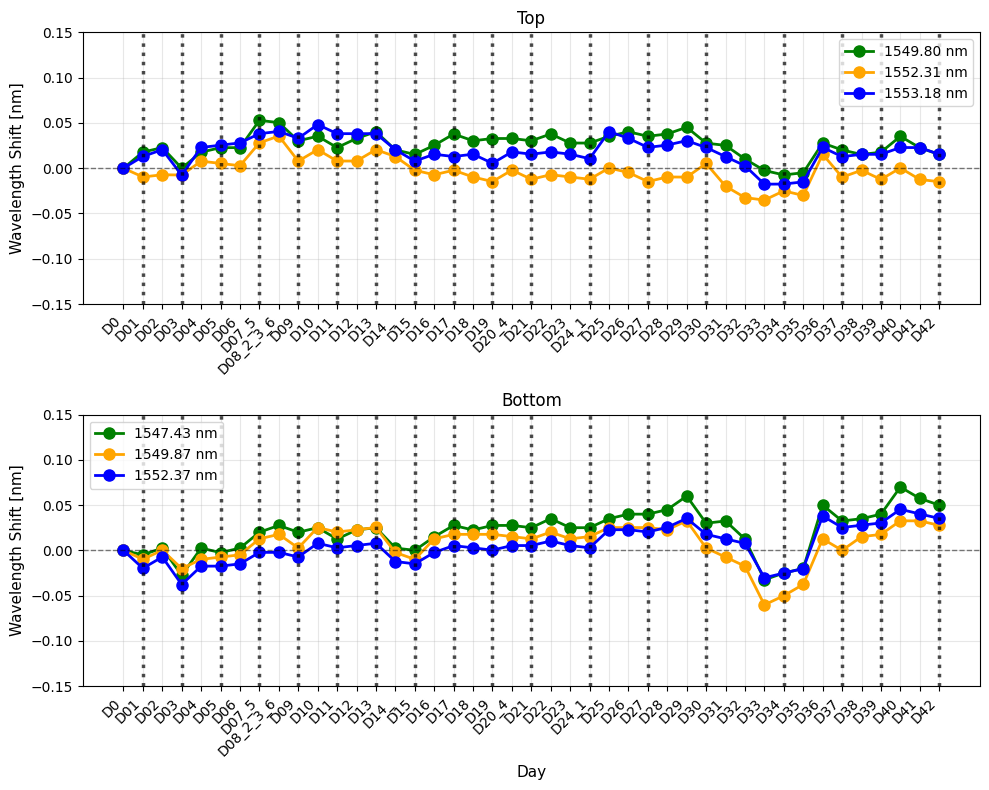

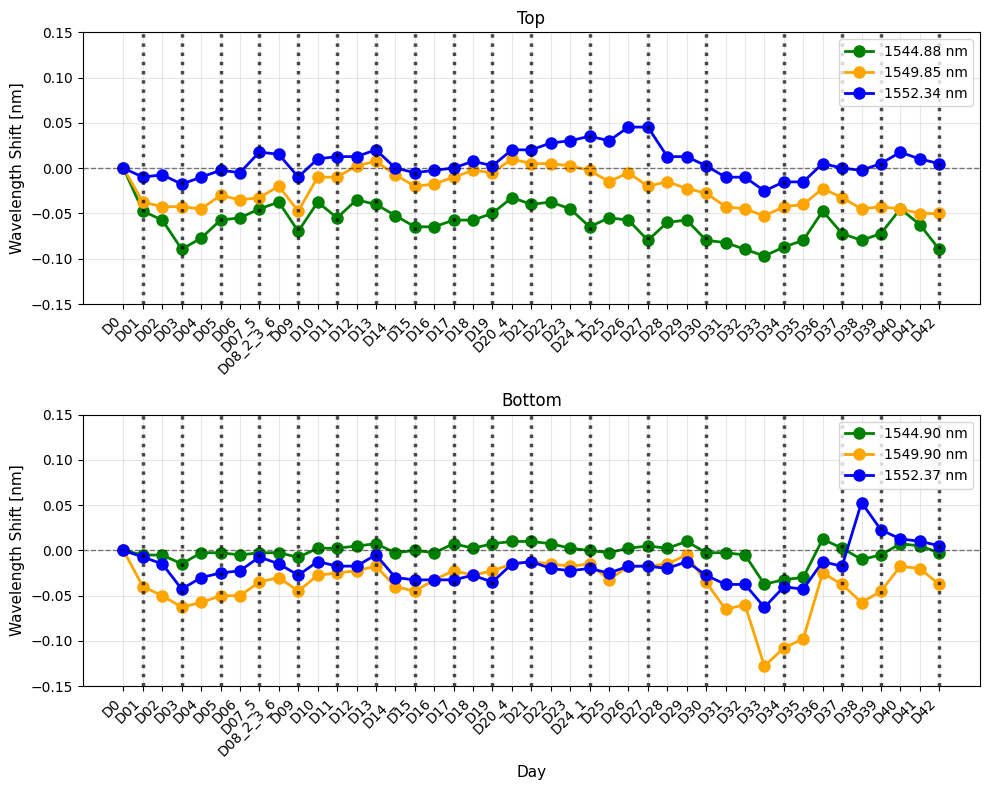

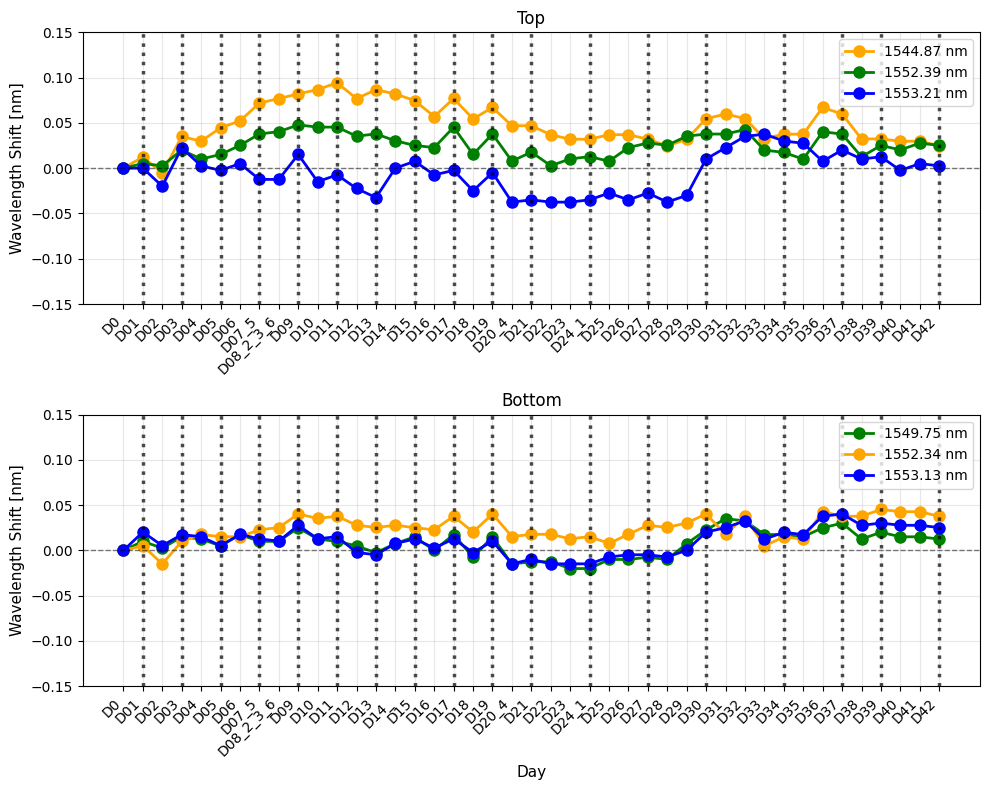

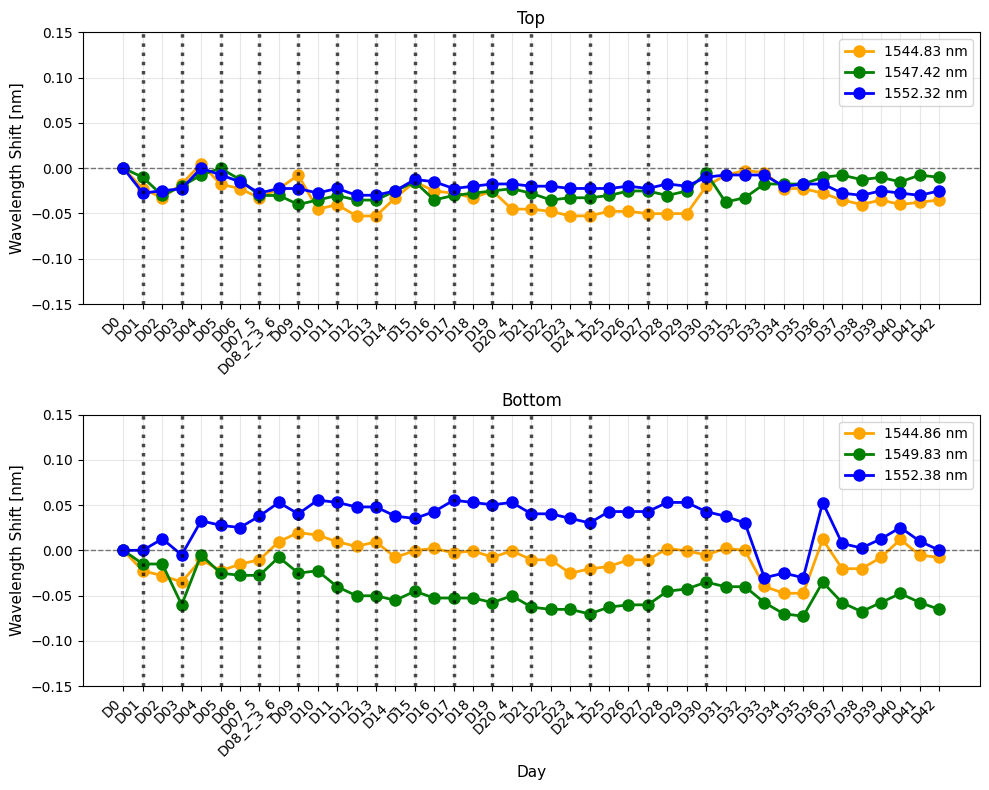

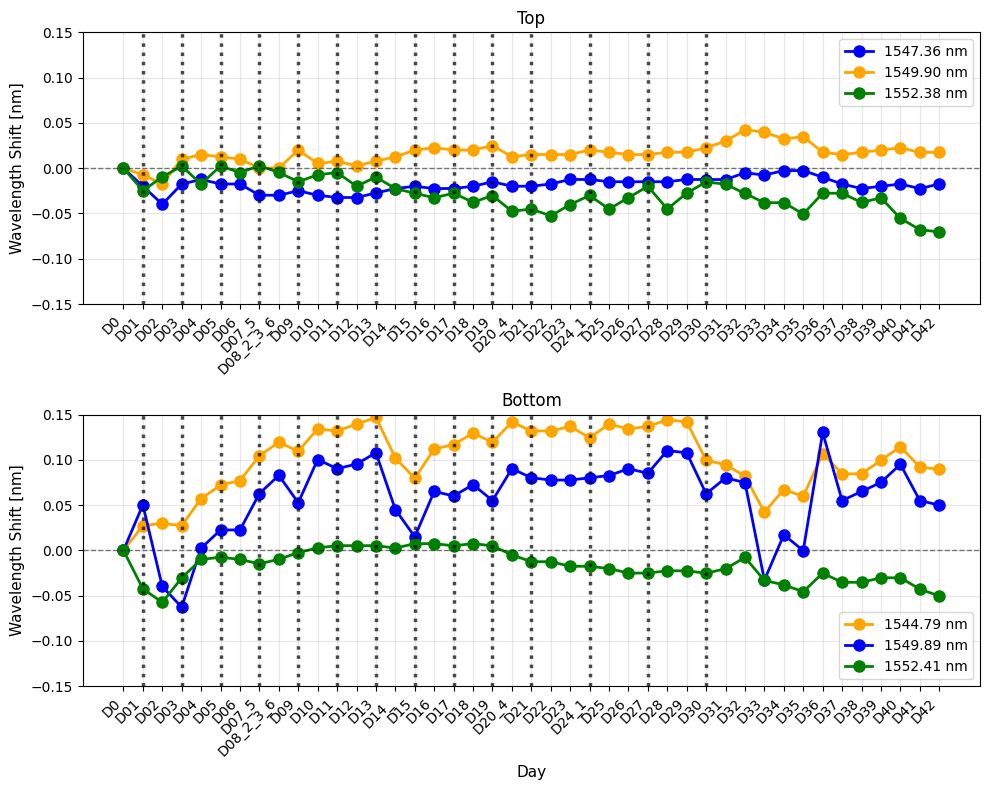

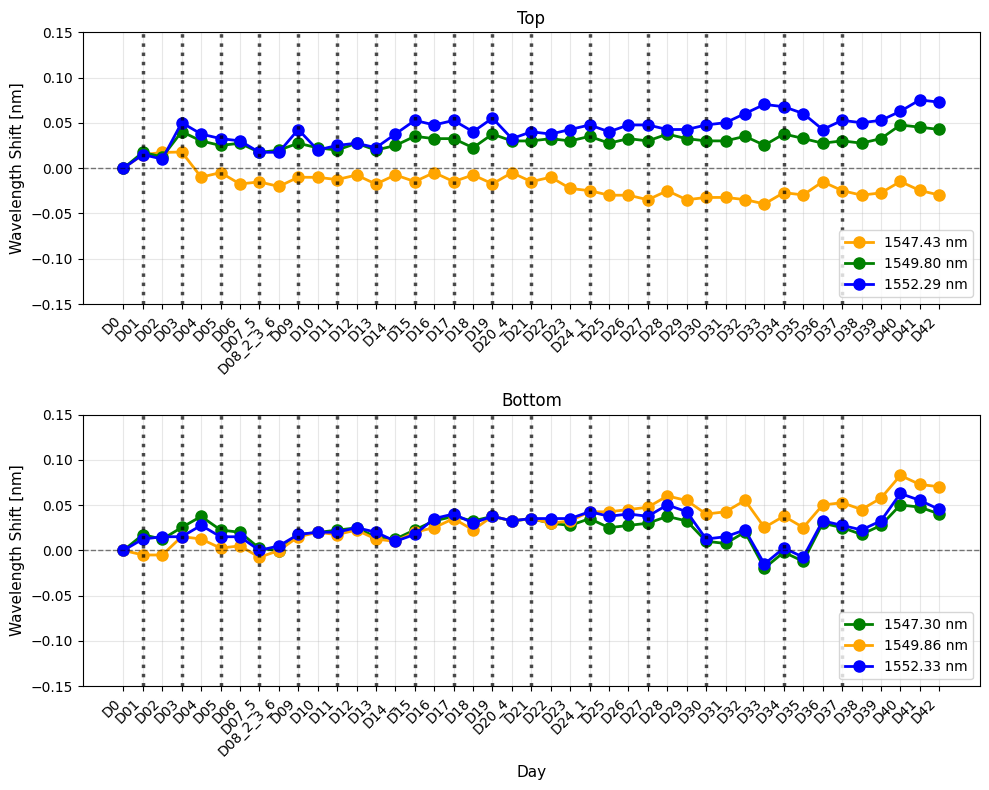

In [19]:
p_level=0.2
y_min=-0.15
y_max=0.15

waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30,34,37,39,42]

power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F1'], 'F1', 
    sensor_dataframes['F2'], 'F2',
    reference_wavelength=1545,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F3'], 'F3', 
    sensor_dataframes['F4'], 'F4',
    reference_wavelength=1547,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F5'], 'F5', 
    sensor_dataframes['F6'], 'F6',
    reference_wavelength=1550,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['orange','green',  'blue'],
    colors2=['green', 'orange', 'blue'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)
waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30]
power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F7'], 'F7', 
    sensor_dataframes['F8'], 'F8',
    reference_wavelength=1550,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['orange','green',   'blue'],
    colors2=['orange','green',  'blue'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)

power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F9'], 'F9', 
    sensor_dataframes['F10'], 'F10',
    reference_wavelength=1545,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['blue','orange','green'],
    colors2=['orange','blue','green'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)
waterDays=[00,1,3,5,7,9,11,13,15,17,19,21,24,27,30,34,37]
power_level_wavelength_tracker_with_reference(
    sensor_dataframes['F11'], 'F11', 
    sensor_dataframes['F12'], 'F12',
    reference_wavelength=1553,
    power_level=p_level-0.1,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['orange','green','blue'],
    colors2=['green','orange','blue'],
    ylim_min1=y_min, ylim_max1=y_max,
    ylim_min2=y_min, ylim_max2=y_max,
    vlines=waterDays
)


In [157]:
def power_level_wavelength_tracker_abs(df1, sensorName1, df2, sensorName2, 
                                        power_level=0.6, colors1=None, colors2=None,
                                        num_crossings1=4, num_crossings2=3,
                                        ylim_min1=None, ylim_max1=None,
                                        ylim_min2=None, ylim_max2=None):
    """
    Track ABSOLUTE VALUE of wavelength shifts at a specific normalized power level across all days.
    
    This function finds where the spectrum crosses a specified power threshold 
    (e.g., 0.6) and tracks the absolute value of wavelength shifts over time relative to Day 1.
    
    Parameters:
    -----------
    df1 : DataFrame
        Sensor dataframe 1 (e.g., sensor_dataframes['F1'])
    sensorName1 : str
        Name of sensor 1
    df2 : DataFrame
        Sensor dataframe 2 (e.g., sensor_dataframes['F2'])
    sensorName2 : str
        Name of sensor 2
    power_level : float, optional
        Normalized power level to track (default: 0.6)
        Must be between 0 and 1 since data is normalized.
    colors1 : list of str, optional
        List of colors for sensor 1 traces (one per crossing)
    colors2 : list of str, optional
        List of colors for sensor 2 traces (one per crossing)
    num_crossings1 : int, optional
        Expected number of power crossings for sensor 1 (default: 4 for odd sensors)
    num_crossings2 : int, optional
        Expected number of power crossings for sensor 2 (default: 3 for even sensors)
    ylim_min1, ylim_max1, ylim_min2, ylim_max2 : float, optional
        Y-axis limits for plots
    """
    # Get wavelength column and day columns
    wavelength_col1 = df1['Wavelength [nm]'].values
    wavelength_col2 = df2['Wavelength [nm]'].values
    
    day_columns = [col for col in df1.columns if col != 'Wavelength [nm]']
    
    # Sort days
    days = sorted(day_columns, 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_shifts = []
    
    def find_power_crossings(wavelength_array, power_array, target_power, num_expected):
        """Find wavelengths where the power crosses the target level."""
        crossings = []
        
        for i in range(len(power_array) - 1):
            if (power_array[i] <= target_power <= power_array[i+1]) or \
               (power_array[i] >= target_power >= power_array[i+1]):
                wl = np.interp(target_power, 
                              [power_array[i], power_array[i+1]], 
                              [wavelength_array[i], wavelength_array[i+1]])
                crossings.append(wl)
        
        crossings.sort()
        
        if len(crossings) > num_expected * 2:
            crossings = crossings[::2]
        
        if len(crossings) >= num_expected:
            step = len(crossings) / num_expected
            selected = [crossings[int(i * step)] for i in range(num_expected)]
            return selected
        else:
            return crossings
    
    # Process sensor 1
    baseline_wavelengths1 = []
    wavelength_data1 = {}
    
    power1_day1 = df1[days[0]].values
    baseline_wavelengths1 = find_power_crossings(wavelength_col1, power1_day1, 
                                                 power_level, num_crossings1)
    
    for idx in range(len(baseline_wavelengths1)):
        wavelength_data1[idx] = []
    
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        
        for idx, baseline_wl in enumerate(baseline_wavelengths1):
            if idx < len(current_crossings):
                wavelength_data1[idx].append(current_crossings[idx])
            else:
                wavelength_data1[idx].append(None)
    
    # Plot sensor 1 with ABSOLUTE VALUE
    for idx in range(len(baseline_wavelengths1)):
        wavelengths = wavelength_data1[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        # Calculate absolute value of shifts
        shifts = [abs(w - baseline) if w is not None else None for w in wavelengths]
        all_shifts.extend([s for s in shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors1 is not None and idx < len(colors1):
            plot_kwargs['color'] = colors1[idx]
        ax[0].plot(x, shifts, 'o-', **plot_kwargs)
    
    ax[0].set_ylabel('|Wavelength Shift| [nm]', fontsize=11)
    ax[0].set_title('Top')
    ax[0].set_ylim(ylim_min1, ylim_max1)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    
    # Process sensor 2
    baseline_wavelengths2 = []
    wavelength_data2 = {}
    
    power2_day1 = df2[days[0]].values
    baseline_wavelengths2 = find_power_crossings(wavelength_col2, power2_day1, 
                                                 power_level, num_crossings2)
    
    for idx in range(len(baseline_wavelengths2)):
        wavelength_data2[idx] = []
    
    for day in days:
        power2 = df2[day].values
        current_crossings = find_power_crossings(wavelength_col2, power2, 
                                                 power_level, num_crossings2)
        
        for idx, baseline_wl in enumerate(baseline_wavelengths2):
            if idx < len(current_crossings):
                wavelength_data2[idx].append(current_crossings[idx])
            else:
                wavelength_data2[idx].append(None)
    
    # Plot sensor 2 with ABSOLUTE VALUE
    for idx in range(len(baseline_wavelengths2)):
        wavelengths = wavelength_data2[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        # Calculate absolute value of shifts
        shifts = [abs(w - baseline) if w is not None else None for w in wavelengths]
        all_shifts.extend([s for s in shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors2 is not None and idx < len(colors2):
            plot_kwargs['color'] = colors2[idx]
        ax[1].plot(x, shifts, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('|Wavelength Shift| [nm]', fontsize=11)
    ax[1].set_title('Bottom')
    ax[1].set_xticks(x)
    ax[1].set_ylim(ylim_min2, ylim_max2)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    
    # Set consistent y-axis limits for both subplots
    # if all_shifts and (ylim_min1 is None or ylim_max1 is None or ylim_min2 is None or ylim_max2 is None):
    #     y_max = max(all_shifts)
    #     y_margin = y_max * 0.1
    #     if ylim_min1 is None or ylim_max1 is None:
    #         ax[0].set_ylim(0, y_max + y_margin)
    #     if ylim_min2 is None or ylim_max2 is None:
    #         ax[1].set_ylim(0, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()


In [158]:
def power_level_wavelength_tracker_with_reference_abs(df1, sensorName1, df2, sensorName2, 
                                                       reference_wavelength, power_level=0.6, 
                                                       colors1=None, colors2=None,
                                                       num_crossings1=4, num_crossings2=3,
                                                       ylim_min1=None, ylim_max1=None,
                                                       ylim_min2=None, ylim_max2=None):
    """
    Track ABSOLUTE VALUE of wavelength shifts at a specific normalized power level with reference correction.
    
    The reference is taken from sensor 1 (odd sensor) at the specified wavelength and 
    subtracted from all other traces in BOTH sensors. The reference trace is NOT plotted.
    Then the absolute value of all corrected shifts is plotted.
    
    Parameters:
    -----------
    df1 : DataFrame
        Sensor dataframe 1 (e.g., sensor_dataframes['F1']) - odd sensor
    sensorName1 : str
        Name of sensor 1
    df2 : DataFrame
        Sensor dataframe 2 (e.g., sensor_dataframes['F2']) - even sensor
    sensorName2 : str
        Name of sensor 2
    reference_wavelength : float
        The wavelength from sensor 1 to use as reference (e.g., 1545).
        The crossing closest to this wavelength will be used as reference.
    power_level : float, optional
        Normalized power level to track (default: 0.6)
    colors1 : list of str, optional
        List of colors for sensor 1 traces (excluding reference)
    colors2 : list of str, optional
        List of colors for sensor 2 traces
    num_crossings1 : int, optional
        Expected number of power crossings for sensor 1 (default: 4)
    num_crossings2 : int, optional
        Expected number of power crossings for sensor 2 (default: 3)
    ylim_min1, ylim_max1 : float, optional
        Y-axis limits for sensor 1 plot
    ylim_min2, ylim_max2 : float, optional
        Y-axis limits for sensor 2 plot
    """
    # Get wavelength column and day columns
    wavelength_col1 = df1['Wavelength [nm]'].values
    wavelength_col2 = df2['Wavelength [nm]'].values
    
    day_columns = [col for col in df1.columns if col != 'Wavelength [nm]']
    
    # Sort days
    days = sorted(day_columns, 
                  key=lambda x: int(x.replace('D', '').split('_')[0]) if x.startswith('D') and x.replace('D', '').split('_')[0].isdigit() else float('inf'))
    
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    
    # Collect all data to determine global y-axis limits
    all_corrected = []
    
    def find_power_crossings(wavelength_array, power_array, target_power, num_expected):
        """Find wavelengths where the power crosses the target level."""
        crossings = []
        
        for i in range(len(power_array) - 1):
            if (power_array[i] <= target_power <= power_array[i+1]) or \
               (power_array[i] >= target_power >= power_array[i+1]):
                wl = np.interp(target_power, 
                              [power_array[i], power_array[i+1]], 
                              [wavelength_array[i], wavelength_array[i+1]])
                crossings.append(wl)
        
        crossings.sort()
        
        if len(crossings) > num_expected * 2:
            crossings = crossings[::2]
        
        if len(crossings) >= num_expected:
            step = len(crossings) / num_expected
            selected = [crossings[int(i * step)] for i in range(num_expected)]
            return selected
        else:
            return crossings
    
    # Process sensor 1 to get all baseline wavelengths
    power1_day1 = df1[days[0]].values
    baseline_wavelengths1 = find_power_crossings(wavelength_col1, power1_day1, 
                                                 power_level, num_crossings1)
    
    # Find reference crossing index (closest to reference_wavelength)
    ref_idx1 = 0
    min_diff = float('inf')
    for idx, wl in enumerate(baseline_wavelengths1):
        diff = abs(wl) - abs(reference_wavelength)
        if diff < min_diff:
            min_diff = diff
            ref_idx1 = idx
    
    # Get reference trace shifts from sensor 1
    ref_wavelength_data = []
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        if ref_idx1 < len(current_crossings):
            ref_wavelength_data.append(current_crossings[ref_idx1])
        else:
            ref_wavelength_data.append(None)
    
    # Calculate reference shifts
    baseline_ref = ref_wavelength_data[0] if ref_wavelength_data[0] is not None else 0
    ref_shifts = [w - baseline_ref if w is not None else None for w in ref_wavelength_data]
    
    # Process sensor 1 - plot all crossings EXCEPT reference
    wavelength_data1 = {}
    for idx in range(len(baseline_wavelengths1)):
        wavelength_data1[idx] = []
    
    for day in days:
        power1 = df1[day].values
        current_crossings = find_power_crossings(wavelength_col1, power1, 
                                                 power_level, num_crossings1)
        for idx, baseline_wl in enumerate(baseline_wavelengths1):
            if idx < len(current_crossings):
                wavelength_data1[idx].append(current_crossings[idx])
            else:
                wavelength_data1[idx].append(None)
    
    # Plot sensor 1 (skip reference crossing) with ABSOLUTE VALUE
    plotted_color_idx = 0
    for idx in range(len(baseline_wavelengths1)):
        # Skip the reference crossing
        if idx == ref_idx1:
            continue
        
        wavelengths = wavelength_data1[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        
        # Subtract reference shift and take absolute value
        corrected_shifts = []
        for i in range(len(shifts)):
            if shifts[i] is not None and ref_shifts[i] is not None:
                corrected_shifts.append(abs(shifts[i] - ref_shifts[i]))
            else:
                corrected_shifts.append(None)
        
        all_corrected.extend([s for s in corrected_shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors1 is not None and plotted_color_idx < len(colors1):
            plot_kwargs['color'] = colors1[plotted_color_idx]
        ax[0].plot(x, corrected_shifts, 'o-', **plot_kwargs)
        plotted_color_idx += 1
    
    ax[0].set_ylabel('|Wavelength Shift| [nm]', fontsize=11)
    ax[0].set_title('Top')
    ax[0].set_ylim(ylim_min1, ylim_max1)
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(days, rotation=45, ha='right')
    ax[0].legend(loc='best')
    ax[0].grid(True, alpha=0.3)
    
    # Process sensor 2 with SAME reference shift from sensor 1
    power2_day1 = df2[days[0]].values
    baseline_wavelengths2 = find_power_crossings(wavelength_col2, power2_day1, 
                                                 power_level, num_crossings2)
    
    wavelength_data2 = {}
    for idx in range(len(baseline_wavelengths2)):
        wavelength_data2[idx] = []
    
    for day in days:
        power2 = df2[day].values
        current_crossings = find_power_crossings(wavelength_col2, power2, 
                                                 power_level, num_crossings2)
        for idx, baseline_wl in enumerate(baseline_wavelengths2):
            if idx < len(current_crossings):
                wavelength_data2[idx].append(current_crossings[idx])
            else:
                wavelength_data2[idx].append(None)
    
    # Plot sensor 2 with reference correction and ABSOLUTE VALUE
    for idx in range(len(baseline_wavelengths2)):
        wavelengths = wavelength_data2[idx]
        baseline = wavelengths[0] if wavelengths[0] is not None else 0
        shifts = [w - baseline if w is not None else None for w in wavelengths]
        
        # Subtract SAME reference shift from sensor 1 and take absolute value
        corrected_shifts = []
        for i in range(len(shifts)):
            if shifts[i] is not None and ref_shifts[i] is not None:
                corrected_shifts.append(abs(shifts[i] - ref_shifts[i]))
            else:
                corrected_shifts.append(None)
        
        all_corrected.extend([s for s in corrected_shifts if s is not None])
        
        x = range(len(days))
        plot_kwargs = {'linewidth': 2, 'markersize': 8, 
                      'label': f'{baseline:.2f} nm'}
        if colors2 is not None and idx < len(colors2):
            plot_kwargs['color'] = colors2[idx]
        ax[1].plot(x, corrected_shifts, 'o-', **plot_kwargs)
    
    ax[1].set_xlabel('Day', fontsize=11)
    ax[1].set_ylabel('|Wavelength Shift| [nm]', fontsize=11)
    ax[1].set_title('Bottom')
    ax[1].set_xticks(x)
    ax[1].set_ylim(ylim_min2, ylim_max2)
    ax[1].set_xticklabels(days, rotation=45, ha='right')
    ax[1].legend(loc='best')
    ax[1].grid(True, alpha=0.3)
    
    # Set consistent y-axis limits if not specified
    # if all_corrected and (ylim_min1 is None or ylim_max1 is None or ylim_min2 is None or ylim_max2 is None):
    #     y_max = max(all_corrected)
    #     y_margin = y_max * 0.1
    #     if ylim_min1 is None or ylim_max1 is None:
    #         ax[0].set_ylim(0, y_max + y_margin)
    #     if ylim_min2 is None or ylim_max2 is None:
    #         ax[1].set_ylim(0, y_max + y_margin)
    
    plt.tight_layout()
    plt.show()


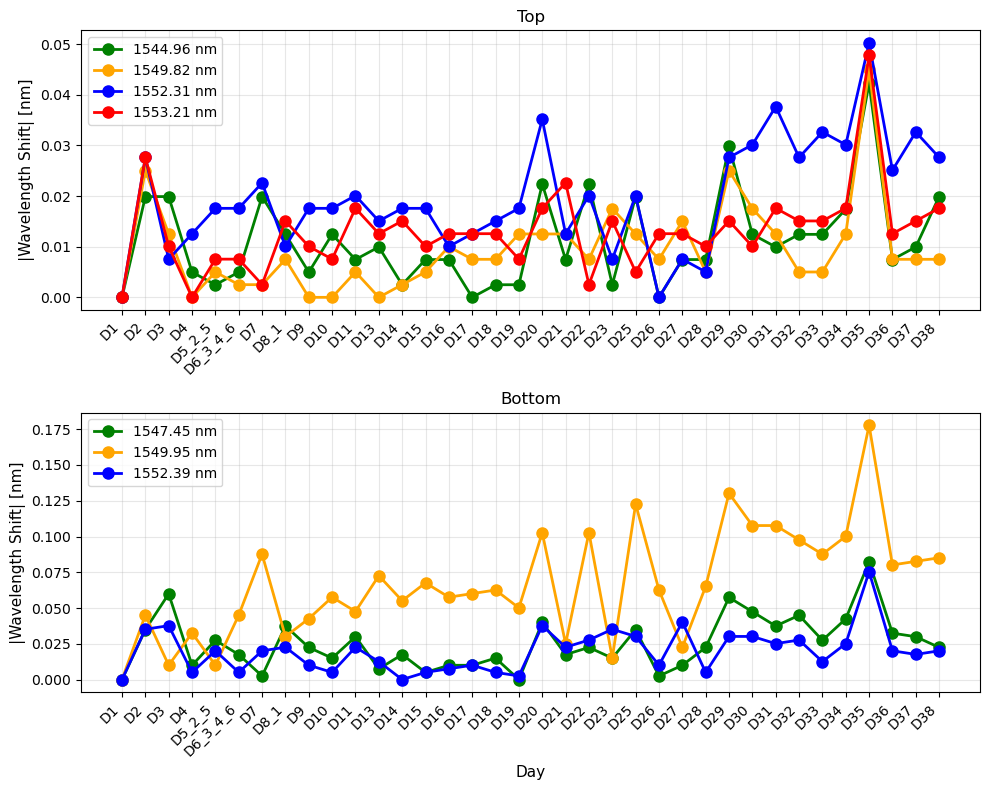

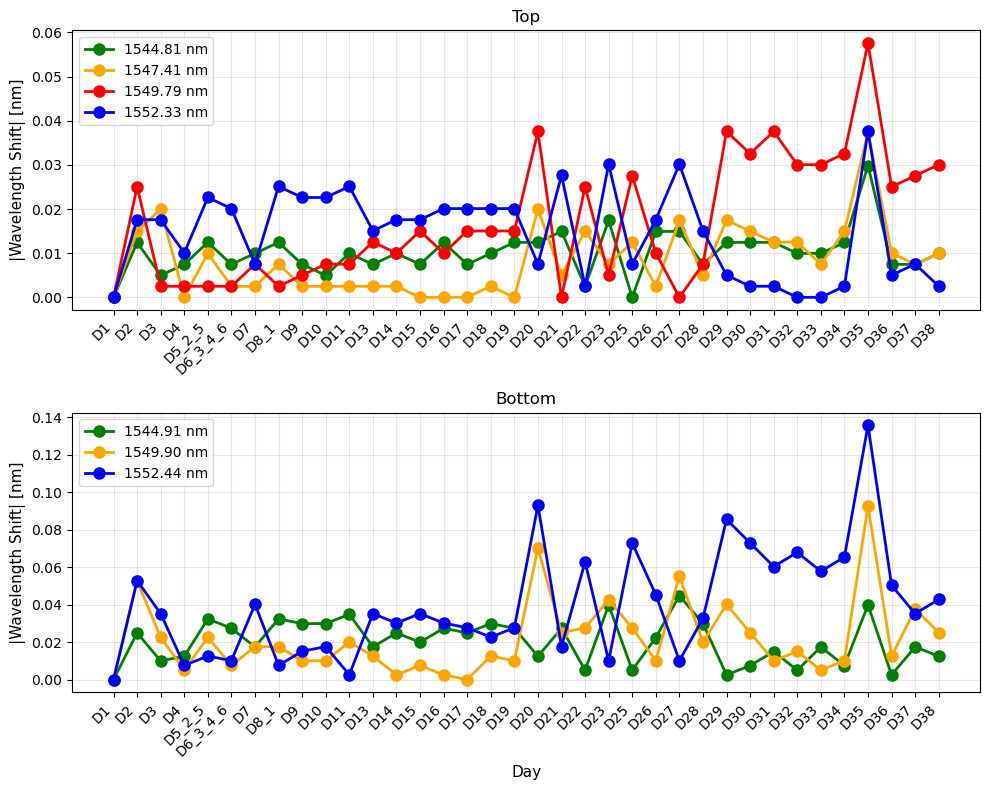

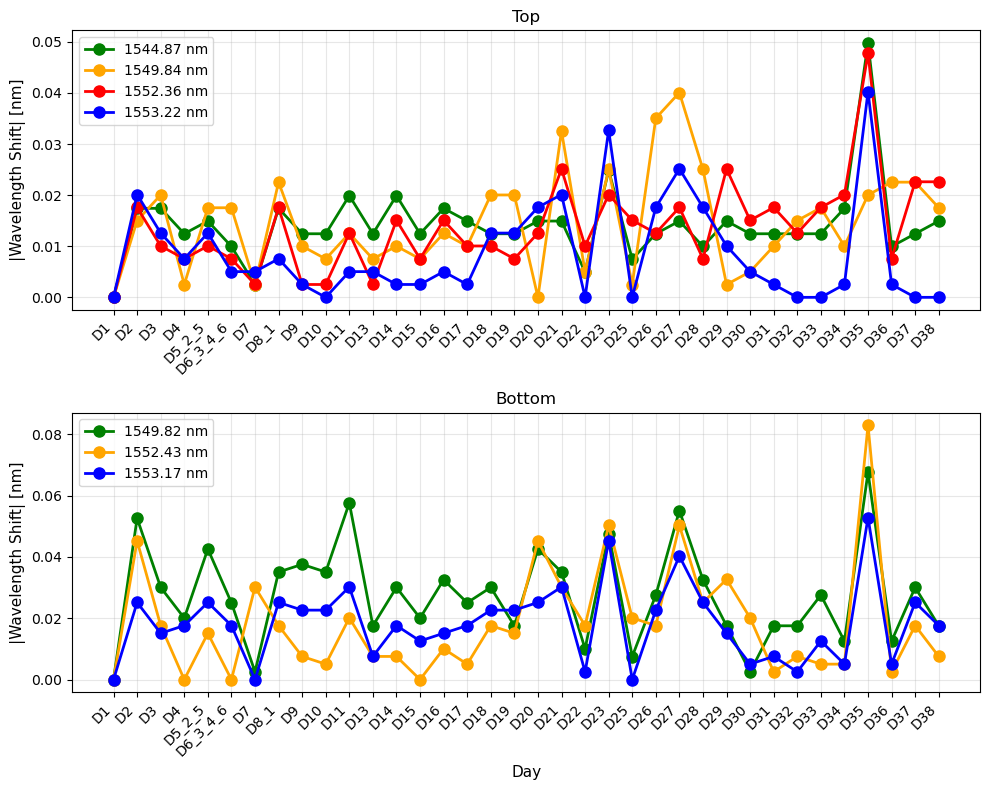

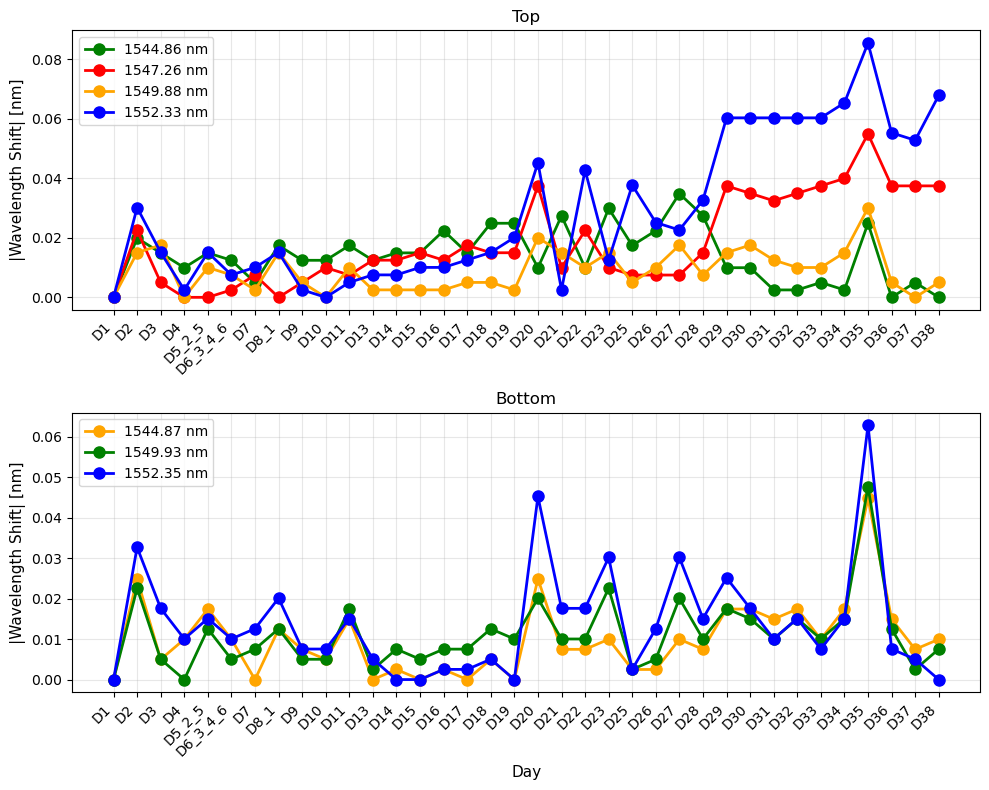

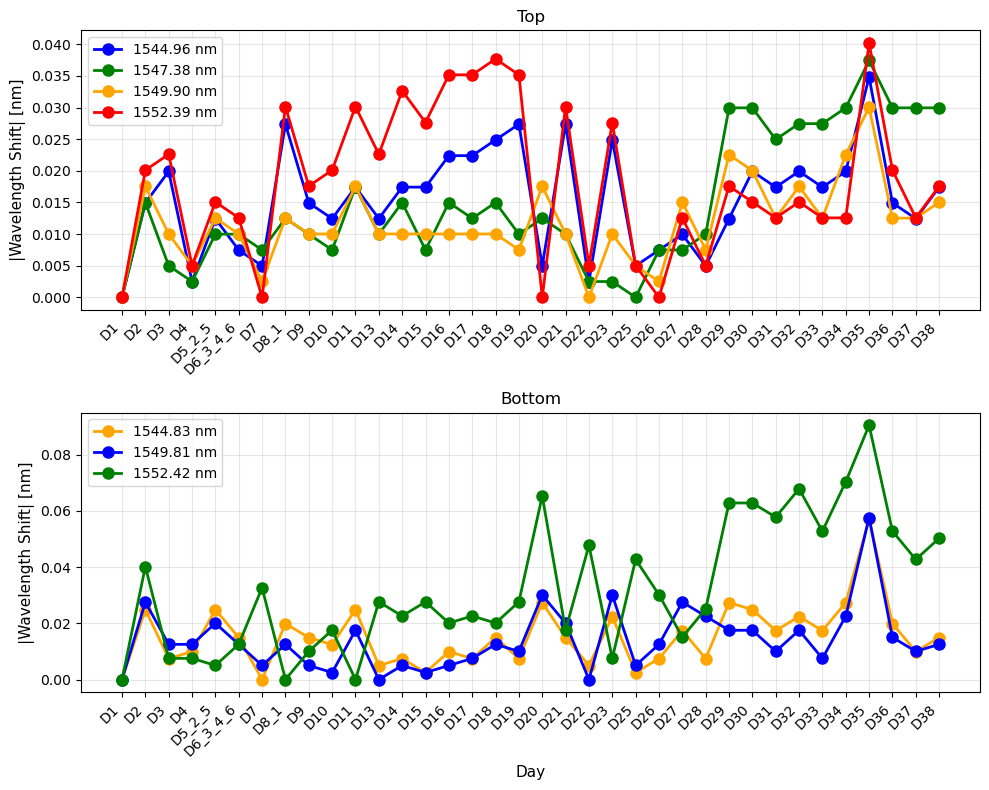

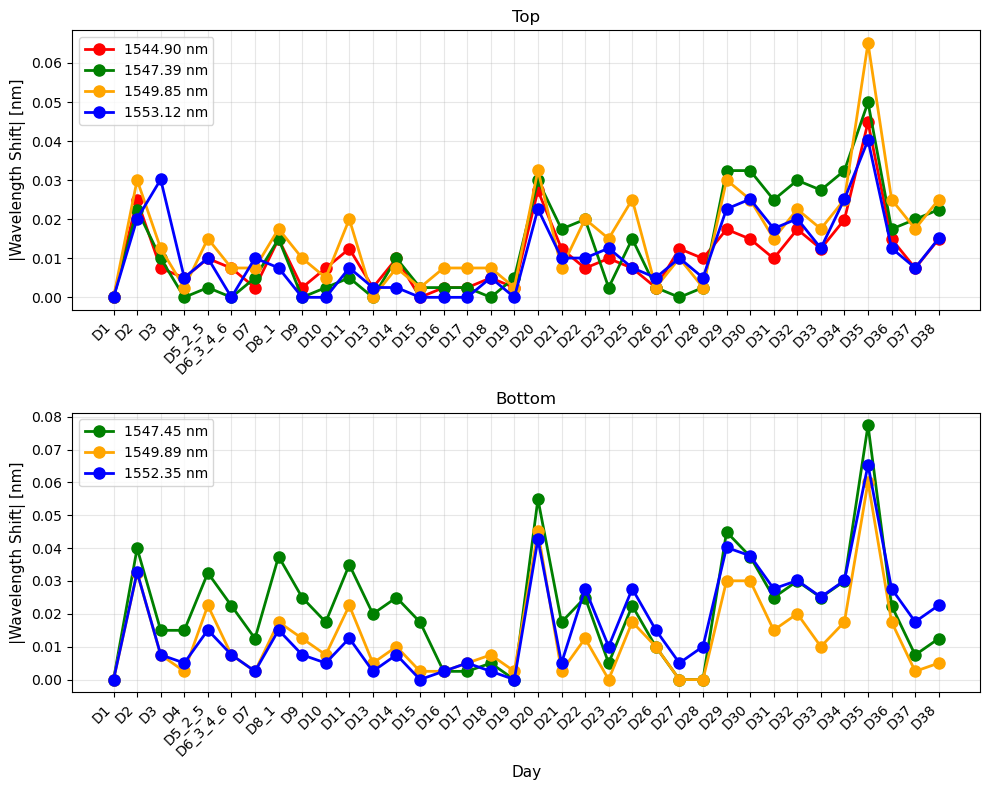

In [162]:
p_level=0.2
y_min=0
y_max=0.18

power_level_wavelength_tracker_abs(
    sensor_dataframes['F1'], 'F1', 
    sensor_dataframes['F2'], 'F2',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green', 'orange', 'blue', 'red'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)

power_level_wavelength_tracker_abs(
    sensor_dataframes['F3'], 'F3', 
    sensor_dataframes['F4'], 'F4',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green', 'orange', 'red', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)

power_level_wavelength_tracker_abs(
    sensor_dataframes['F5'], 'F5', 
    sensor_dataframes['F6'], 'F6',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green', 'orange', 'red', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)

power_level_wavelength_tracker_abs(
    sensor_dataframes['F7'], 'F7', 
    sensor_dataframes['F8'], 'F8',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['green','red', 'orange',  'blue'],
    colors2=['orange','green',  'blue'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)

power_level_wavelength_tracker_abs(
    sensor_dataframes['F9'], 'F9', 
    sensor_dataframes['F10'], 'F10',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['blue','green','orange','red'],
    colors2=['orange','blue','green'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)

power_level_wavelength_tracker_abs(
    sensor_dataframes['F11'], 'F11', 
    sensor_dataframes['F12'], 'F12',
    power_level=p_level,
    num_crossings1=4,  
    num_crossings2=3,  
    colors1=['red','green','orange','blue'],
    colors2=['green','orange','blue'],
    # ylim_min1=y_min,ylim_max1=y_max,
    # ylim_min2=y_min,ylim_max2=y_max,
)


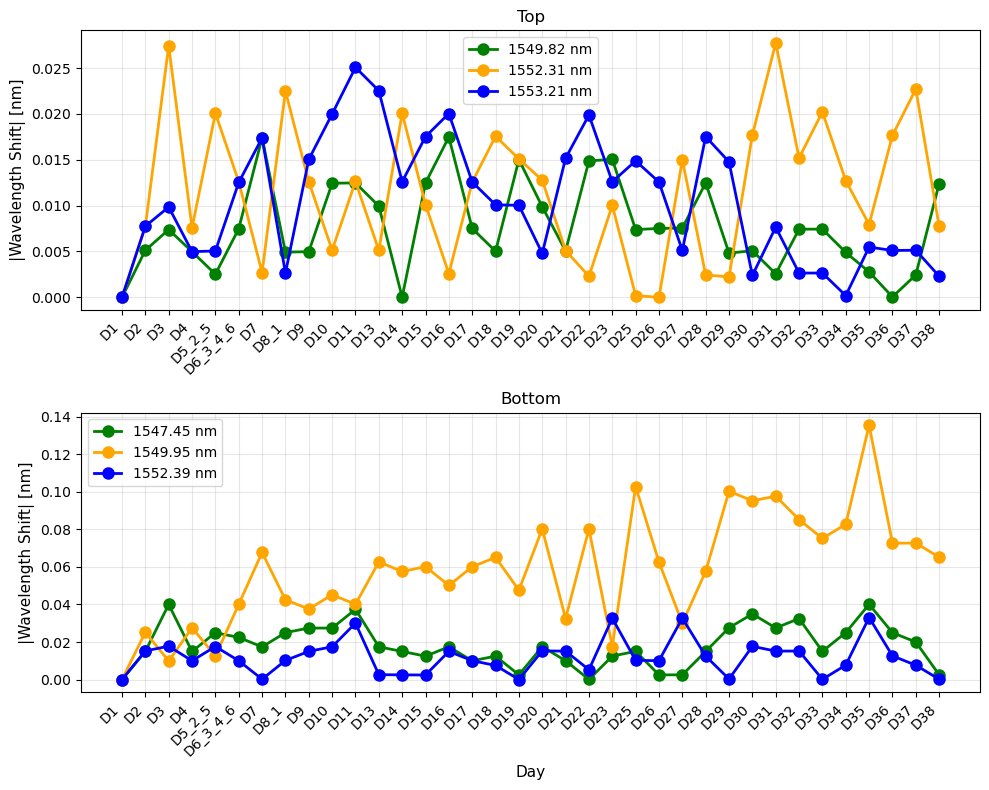

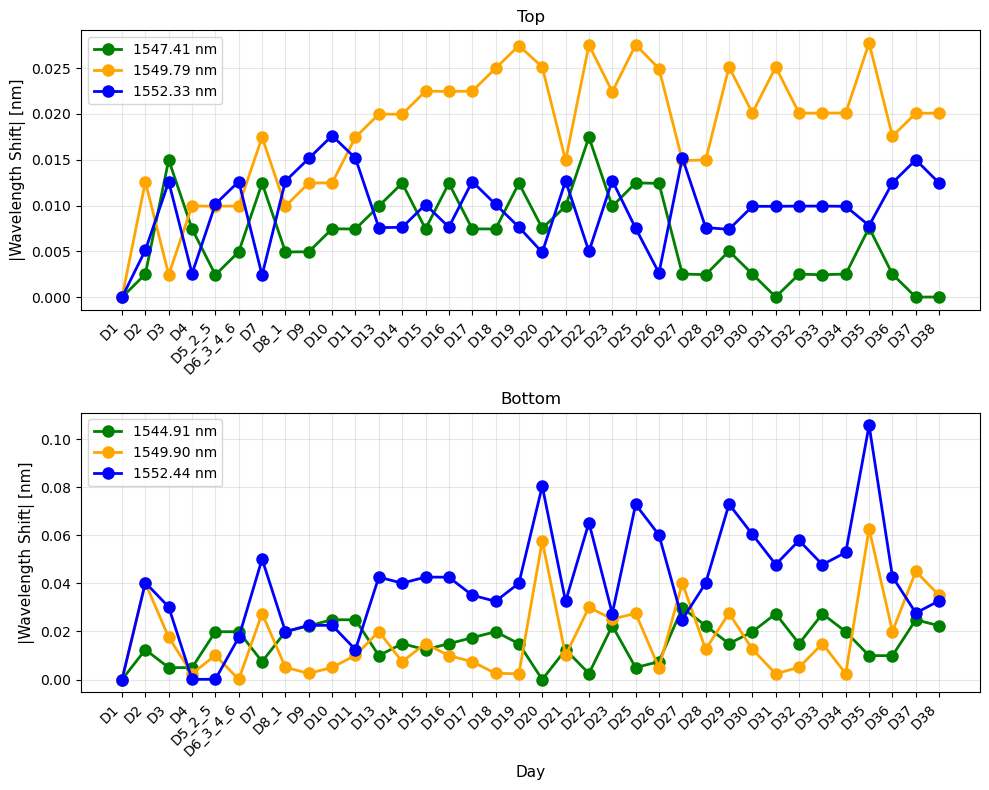

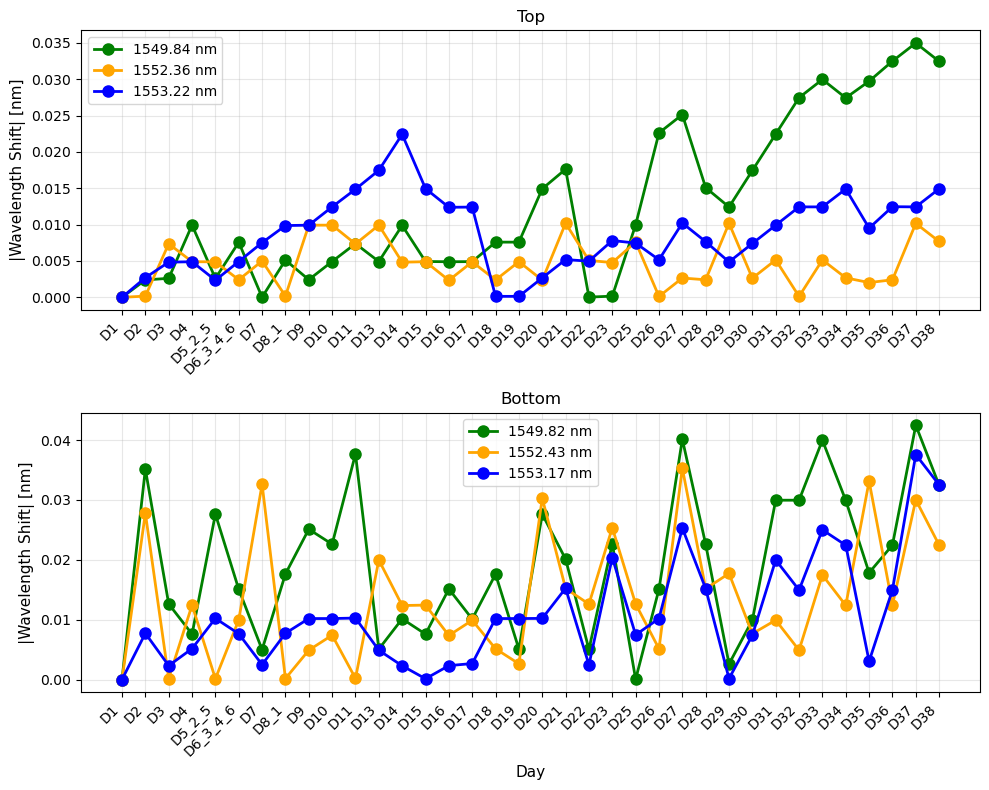

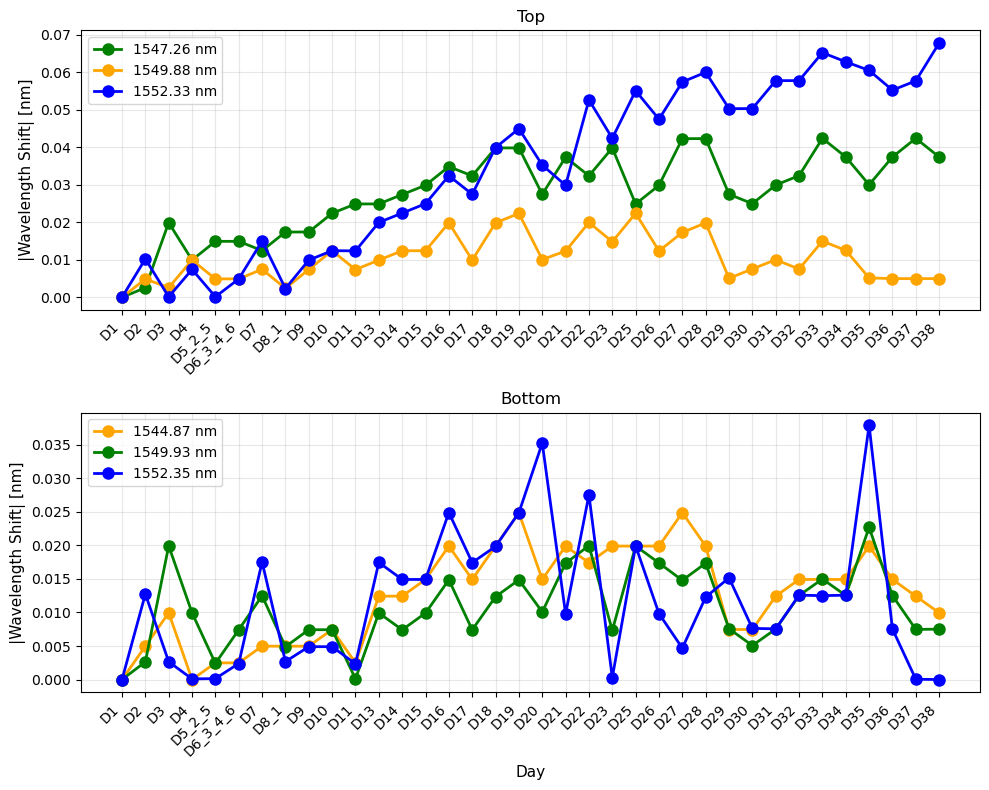

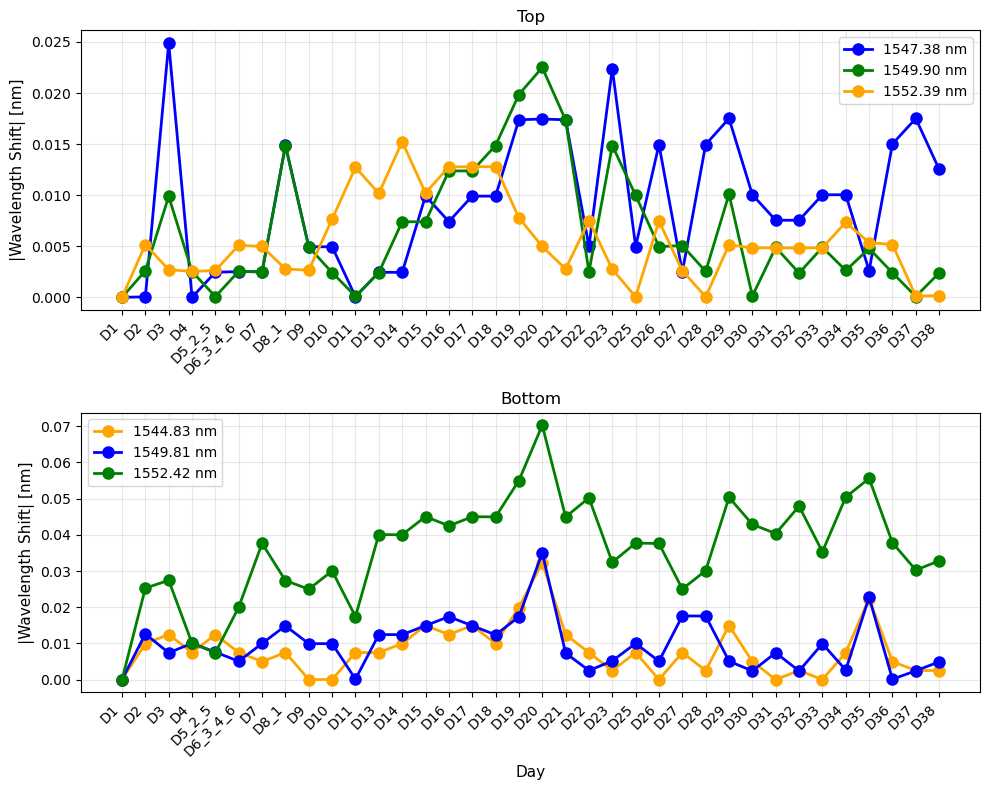

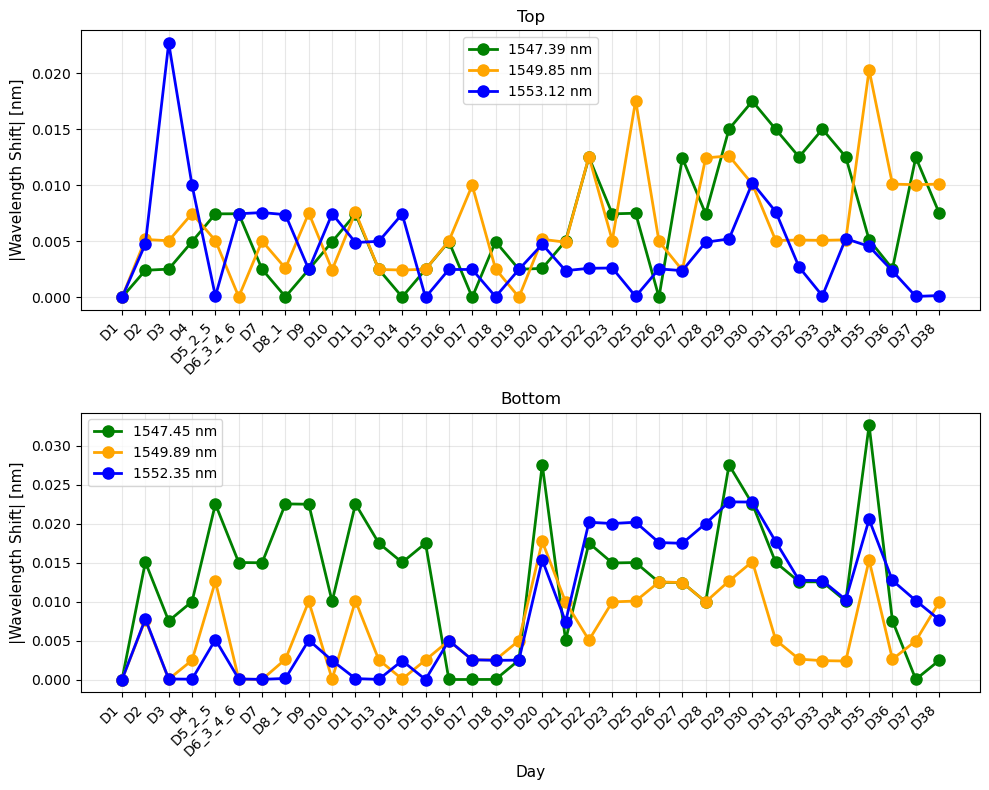

In [165]:
p_level=0.2
y_min=0
y_max=0.14


power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F1'], 'F1', 
    sensor_dataframes['F2'], 'F2',
    reference_wavelength=1545,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)

power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F3'], 'F3', 
    sensor_dataframes['F4'], 'F4',
    reference_wavelength=1547,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)

power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F5'], 'F5', 
    sensor_dataframes['F6'], 'F6',
    reference_wavelength=1550,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)

power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F7'], 'F7', 
    sensor_dataframes['F8'], 'F8',
    reference_wavelength=1550,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['orange', 'green', 'blue'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)

power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F9'], 'F9', 
    sensor_dataframes['F10'], 'F10',
    reference_wavelength=1545,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['blue', 'green', 'orange'],
    colors2=['orange', 'blue', 'green'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)

power_level_wavelength_tracker_with_reference_abs(
    sensor_dataframes['F11'], 'F11', 
    sensor_dataframes['F12'], 'F12',
    reference_wavelength=1553,
    power_level=p_level,
    num_crossings1=4,
    num_crossings2=3,
    colors1=['green', 'orange', 'blue'],
    colors2=['green', 'orange', 'blue'],
    # ylim_min1=y_min, ylim_max1=y_max,
    # ylim_min2=y_min, ylim_max2=y_max
)
